# Sistema de alerta de estaciones sin bicis con aprendizaje en flujo de datos

### Detección de *data drift* y *concept drift* en el sistema de bicicletas compartidas de Toulouse

**Asignatura:** Aprendizaje Automático en Series Temporales y Flujos de Datos · Máster en Inteligencia Artificial Aplicada · Universidad Carlos III de Madrid · Curso 2026-2027

**Autores:** Álvaro Alonso Haya · Antonio Ángel Bello Castro · Martín Hernández Tonzán

**Profesor:** José Antonio Iglesias Martínez

---

**Índice**

1. Introducción y motivación
2. Objetivo
3. Trabajos similares
4. Desarrollo
   - 4.1 Flujo de sensores: origen, calidad y construcción
   - 4.2 Análisis del comportamiento del flujo de sensores
   - 4.3 Estrategia de aprendizaje y evaluación
   - 4.4 Elección razonada del modelo de alerta
   - 4.5 El modelo en el flujo real: rendimiento y *concept drift*
   - 4.6 *Data drift* en el flujo real
   - 4.7 *Concept drift* controlado y estrategias de adaptación
   - 4.8 Flujo de avisos de usuarios: clasificación de texto online
   - 4.9 Sistema anticipativo frente a sistema reactivo: ¿quién avisa antes?
5. Resultados
6. Análisis crítico y conclusiones
7. Referencias

## Cómo ejecutar este cuaderno

- **En Google Colab:** *Entorno de ejecución → Ejecutar todas*. La primera celda instala River 0.26.1 (la versión con la que se obtuvieron los resultados). Si al instalarla cambia la versión de `numpy`, la celda reinicia la sesión automáticamente: basta con volver a pulsar *Ejecutar todas*.
- **No hay que subir ningún fichero.** El flujo de sensores se construye a partir del dataset `Bikes`, que River descarga solo, y el flujo de avisos de usuarios se genera dentro del cuaderno con una semilla fija. Los dos se guardan como CSV y se leen con `river.stream.iter_csv`, simulando la llegada de los datos.
- **Duración:** unos 15 minutos en Colab. Lo más lento son las ejecuciones del *Adaptive Random Forest* de los apartados 4.5 a 4.7.

In [498]:
# Instalación de River (versión fija para que los resultados sean reproducibles)
import importlib.metadata as metadata
import os
import sys

numpy_antes = metadata.version("numpy")
%pip install -q river==0.26.1
if "google.colab" in sys.modules and metadata.version("numpy") != numpy_antes:
    print("numpy ha cambiado: se reinicia la sesión. Vuelve a pulsar 'Ejecutar todas'.")
    os.kill(os.getpid(), 9)
else:
    print("River instalado")

Note: you may need to restart the kernel to use updated packages.
River instalado


In [ ]:
# Librerías y estilo de las gráficas
import collections
import math
import re
import time
import unicodedata
import warnings
from itertools import islice, takewhile

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import river
from river import (cluster, compose, datasets, drift, evaluate, feature_extraction, forest, linear_model, metrics,
                   multiclass, naive_bayes, optim, preprocessing, stats, stream, tree)

warnings.filterwarnings("ignore")
print("River:", river.__version__)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 200)
pd.set_option("display.max_rows", 100)

# Paleta y estilo de las gráficas
AZUL, NARANJA, VERDE, ROJO, MORADO, GRIS, SOMBRA, TINTA = ("#2a78d6", "#eb6834", "#1baf7a", "#e34948", "#8a5cc2",
                                                          "#8a8985", "#e6e5e0", "#2b2b2a")
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": SOMBRA, "grid.linewidth": 0.6,
    "axes.edgecolor": GRIS, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "font.size": 9.5,
})

River: 0.26.1


# 1. Introducción y motivación

En los sistemas de bicicletas compartidas el servicio falla de dos formas: el usuario llega a una estación y **no encuentra ninguna bici**, o quiere devolverla y **está llena**. Los operadores intentan evitarlo llevando bicis de unas estaciones a otras en camiones, pero esa redistribución es cara y suele llegar tarde, así que muchas estaciones pasan horas vacías o llenas [1]. A menudo el operador se entera por las quejas de los usuarios, que llegan mezcladas con avisos de averías, problemas con la aplicación o simples consultas.

Decidir cuándo y dónde reponer bicis es un problema de optimización complejo: depende de las bicis disponibles, de las rutas y el coste de los camiones y de la demanda de cada estación, que también habría que predecir, igual que el momento en que una estación se llena. Todo eso queda fuera de este trabajo. Nos centramos en la primera fase, la información que esa decisión necesita: para la estación ***pomme*** de Toulouse, una estimación, actualizada cada 30 minutos, del riesgo de quedarse con 2 bicis o menos dentro de 2 horas, con su probabilidad. No todo vaciado es igual de grave: de madrugada casi nadie busca una bici, y en la hora punta de la tarde sí.

Planteamos dos sistemas que avisan al mismo equipo de redistribución: uno **anticipativo**, que predice el vaciado a partir de los sensores de la estación, y otro **reactivo**, que clasifica las quejas de los usuarios en cuanto llegan y envía a ese equipo las de falta de bicis. La pregunta que cierra el trabajo es si el anticipativo avisa antes. Los dos aprenden de **flujos de datos**: la información llega sin parar y el comportamiento cambia con las vacaciones, la vuelta a clase, el tiempo o los turistas, así que los modelos aprenden instancia a instancia y hay que vigilar si cambian los datos que llegan (***data drift***) o la relación entre esos datos y lo que se predice (***concept drift***), y decidir cómo reaccionar [2].

# 2. Objetivo

El objetivo es diseñar, evaluar y analizar críticamente un sistema de aprendizaje en flujo de datos que ayude a que *pomme* no se quede sin bicis, combinando una alerta anticipativa con la clasificación de las quejas de los usuarios, y que detecte los cambios en los datos y se adapte a ellos.

Para ser fieles a cómo se haría en la realidad, el sistema se **diseña solo con junio**: con ese mes se construye y analiza el flujo, se elige el modelo de alerta y se fijan sus parámetros. Después lo vigilamos de julio a octubre, como si ya estuviera en marcha: si sigue acertando, si cambian los datos y qué días son atípicos. Con un cambio fuerte provocado comprobamos cómo detectarlo y cómo reaccionar y, por último, añadimos el sistema reactivo de las quejas para medir cuál de los dos avisa antes.

# 3. Trabajos similares

**Predicción de la disponibilidad en sistemas de bicicletas compartidas.** La redistribución de bicis es el principal problema operativo de estos sistemas, y predecir qué estaciones se van a quedar vacías o llenas permite anticiparla. BRAVO [1] predice el rango de bicis que necesitará cada estación para planificar la redistribución y muestra que la operación es cara y poco anticipada en la práctica. El dataset que usamos procede del *OpenBikes 2016 Challenge* [3], un concurso de predicción del número de bicis en las estaciones de Toulouse. Estos trabajos son en general por lotes; aquí el problema se plantea **online**, con el modelo actualizándose en cada instancia y vigilando su propia degradación.

# 4. Desarrollo

Los apartados 4.1 a 4.4 construyen el flujo de sensores y diseñan la alerta con los datos de junio. Del 4.5 al 4.7 el sistema ya funciona online: analizamos su rendimiento y los cambios de julio a octubre, y probamos cómo reaccionar ante un cambio fuerte provocado. El 4.8 añade el sistema reactivo, la clasificación de las quejas de los usuarios, y el 4.9 compara cuál de los dos avisa antes.

## Conceptos clave y cómo leer el desarrollo

**Flujo de datos y aprendizaje online.** En un flujo, los datos llegan **de uno en uno y sin fin**: no se pueden guardar todos ni recorrer varias veces. Por eso el modelo se usa y se actualiza a la vez: con cada instancia *x* primero **predice** (`predict_one(x)`) y, cuando conoce la etiqueta *y*, **aprende** (`learn_one(x, y)`). En River todos los modelos tienen estos dos métodos.

**Evaluación *prequential* (*test-then-train*).** Como no hay un conjunto de test separado, cada instancia sirve primero para evaluar (se compara la predicción con la etiqueta) y después para entrenar. La métrica se va acumulando a lo largo del flujo y muestra cómo evoluciona el modelo. En nuestro caso **la etiqueta llega tarde** (2 horas en los sensores, 1 hora en los avisos), así que el modelo predice ahora y solo aprende cuando llega la etiqueta (apartado 4.3.1).

***Baseline*.** Un modelo de referencia sin aprendizaje (por ejemplo, "dentro de 2 horas la estación seguirá como ahora"). Un modelo solo aporta si lo supera.

***Model drift*: los dos tipos de cambio.** Si *X* son las variables de entrada e *y* la etiqueta:
- ***Data drift***: cambia la distribución de las entradas, **P(X)** (por ejemplo, en vacaciones se usa menos la estación, o en verano llegan avisos en inglés). Se puede vigilar **sin etiquetas**, mirando directamente las variables. No siempre perjudica al modelo.
- ***Concept drift***: cambia la relación entre entradas y etiqueta, **P(y \| X)** (las mismas condiciones llevan a otro resultado; por ejemplo, el mismo texto pasa a tener otra categoría). El modelo empeora. Se detecta vigilando **su error**, que solo se conoce cuando llega la etiqueta.
- Según su forma, un cambio puede ser **abrupto** (de un día para otro), **gradual**, **incremental** o **recurrente** (se repite, como el ciclo diario).

**Detectores de drift.** Reciben una señal observación a observación (una variable de entrada o el bit de error del modelo, 1 = fallo) y dan una **alarma** cuando su estadístico supera un umbral. Algunos tienen además un nivel previo de ***warning***. Un detector es bueno si detecta los cambios reales con **poco retardo** y da **pocas falsas alarmas**; las dos cosas compiten, y los parámetros del detector deciden el equilibrio.

**Estrategias de adaptación.** Cuando hay *concept drift* se puede: seguir aprendiendo online sin más; reiniciar el modelo cuando salta un detector; sustituir solo la parte afectada (Hoeffding Adaptive Tree); usar ensembles que renuevan sus miembros (ARF); u olvidar progresivamente lo antiguo (factor de olvido).

**Cómo está escrito cada apartado:** primero **para qué** se hace, después el código (cada celda empieza con un comentario que dice qué hace) y al final, en viñetas, lo que se concluye, que es lo que se usa en los apartados siguientes y en las conclusiones finales.

## 4.1 Flujo de sensores: origen, calidad y construcción

### 4.1.1 Dataset

Usamos el dataset `Bikes` de River (*OpenBikes 2016 Challenge* [3]): lecturas reales del número de bicis de 5 estaciones de Toulouse, recogidas consultando periódicamente las APIs de las estaciones y completadas con el tiempo meteorológico de la ciudad. River descarga el CSV la primera vez. Cada fila es una **lectura** del estado de una estación:

| Columna | Significado |
|---|---|
| `moment` | fecha y hora de la lectura |
| `station` | estación (5 en total) |
| `bikes` | número de bicis disponibles en ese momento |
| `clouds`, `description`, `humidity`, `pressure`, `temperature`, `wind` | tiempo meteorológico en Toulouse en ese momento (nubosidad %, descripción, humedad %, presión hPa, temperatura °C, viento m/s) |

In [ ]:
# Descarga del dataset Bikes (solo la primera vez) y carga con pandas, solo para analizarlo (los modelos lo leerán como flujo)
dataset = datasets.Bikes()
dataset.download()
df = pd.read_csv(dataset.path, parse_dates=["moment"])
print(df.shape)
df.head()

(182470, 9)


,moment,bikes,station,clouds,description,humidity,pressure,temperature,wind
0,2016-04-01 00:00:07,1,metro-canal-du-midi,75,light rain,81,1017.0,6.54,9.3
1,2016-04-01 00:00:16,3,place-des-carmes,75,light rain,81,1017.0,6.54,9.3
2,2016-04-01 00:00:35,3,place-des-carmes,75,light rain,81,1017.0,6.54,9.3
3,2016-04-01 00:04:50,2,place-esquirol,75,light rain,81,1017.0,6.54,9.3
4,2016-04-01 00:05:29,2,place-esquirol,75,light rain,81,1017.0,6.54,9.3


### 4.1.2 Calidad del CSV y elección de la estación y del periodo

In [ ]:
# Calidad del CSV: ausentes, duplicados, intervalo entre lecturas de cada estación y cortes en la recogida
print("Valores ausentes:", int(df.isna().sum().sum()), "| filas duplicadas:", df.duplicated().sum())

df = df.sort_values(["station", "moment"])
intervalo = df.groupby("station")["moment"].diff().dt.total_seconds() / 60
print("Intervalo mediano entre lecturas (min):", intervalo.groupby(df["station"]).median().round(1).to_dict())

# Cortes: huecos de más de 2 horas sin ninguna lectura (de ninguna estación)
todas = df["moment"].sort_values().reset_index(drop=True)
hueco = todas.diff()
cortes = hueco[hueco > pd.Timedelta(hours=2)]
dias_sin_datos = (cortes.dt.total_seconds() / 86400).groupby(todas[cortes.index].dt.month).sum().round(1)
print(f"Cortes de más de 2 h: {len(cortes)} | días sin datos por mes:", dias_sin_datos.to_dict())

Valores ausentes: 0 | filas duplicadas: 19
Intervalo mediano entre lecturas (min): {'metro-canal-du-midi': 10.0, 'place-des-carmes': 5.8, 'place-esquirol': 3.0, 'place-jeanne-darc': 10.0, 'pomme': 3.0}
Cortes de más de 2 h: 13 | días sin datos por mes: {4: 9.3, 5: 18.9, 9: 1.0}


In [ ]:
# Comparación de las 5 estaciones y lecturas de la elegida (pomme) en el periodo elegido
resumen_est = df.groupby("station").agg(
    lecturas=("bikes", "size"),
    bicis_media=("bikes", "mean"),
    bicis_max=("bikes", "max"),
    pct_lecturas_vacia=("bikes", lambda s: 100 * (s == 0).mean()),
).round(1).sort_values("lecturas", ascending=False)

ESTACION = "pomme"
INICIO = "2016-06-01"
pomme = (df[(df["station"] == ESTACION) & (df["moment"] >= INICIO)]
         .drop(columns="station").drop_duplicates()
         .sort_values("moment").reset_index(drop=True))
print(f"Lecturas de {ESTACION} desde {INICIO}: {len(pomme):,}")
resumen_est

Lecturas de pomme desde 2016-06-01: 38,358


,lecturas,bicis_media,bicis_max,pct_lecturas_vacia
station,,,,
pomme,50532,8.3,18,11.5
place-esquirol,49236,16.0,34,9.2
place-des-carmes,31127,7.5,20,13.2
metro-canal-du-midi,26329,9.6,25,4.1
place-jeanne-darc,25246,5.7,25,9.2


- No hay valores ausentes y solo hay 19 filas duplicadas exactas, que se eliminan. El CSV **mezcla las 5 estaciones** en orden de llegada y las lecturas **no llegan a intervalos regulares**: la mediana va de 3 minutos en las estaciones con más movimiento a 10 en las más tranquilas.
- **Hay cortes en la recogida**, casi todos en abril y mayo (de horas a 7 días seguidos) y uno de un día en septiembre. Por eso usamos el periodo **del 1 de junio al 5 de octubre de 2016**: con abril y mayo el flujo tendría saltos de varios días, que un detector de drift confundiría con cambios reales.
- Elegimos ***pomme***: es la estación con más lecturas y una de las que más tiempo pasa vacía (11,5 % de las lecturas), así que el problema de alerta tiene sentido.

### 4.1.3 Construcción del flujo regular: una instancia cada 30 minutos

Como las lecturas llegan a intervalos irregulares, construimos un flujo **regular**: cada 30 minutos llega una instancia con el **estado de la estación en ese momento** (la última lectura de la media hora). Así, además, los fallos del modelo no llegan en rachas de lecturas casi repetidas, que los detectores de drift confundirían con cambios.

**Variables de cada instancia** (solo información disponible en el instante *t*):

| Variable | Descripción |
|---|---|
| `momento` | instante *t* (solo para registro; no se usa como variable del modelo) |
| `bicis` | bicis disponibles en *t* |
| `tendencia_1h` | `bicis(t) − bicis(t − 1 h)`: si la estación se está vaciando o llenando |
| `movimientos_30min` | bicis que han entrado o salido en la última media hora, calculadas con las lecturas originales: mide el **uso** de la estación |
| `hora` | hora del día en decimal (8.5 = 8:30) |
| `dia_semana`, `es_finde`, `es_festivo` | calendario (festivos en Francia en el periodo: 14 de julio y 15 de agosto) |
| `temperatura`, `humedad`, `viento`, `nubes`, `llueve` | tiempo meteorológico en *t* (`llueve` = la descripción incluye lluvia, llovizna o tormenta) |

**Etiqueta:** `pocas_bicis_2h` = 1 si en *t* + 2 h hay **2 bicis o menos**. **Llega con 2 horas de retraso**: en *t* el sistema predice y solo en *t* + 2 h sabe si acertó (apartado 4.3). El horizonte de 2 horas da tiempo a reponer bicis o a avisar a los usuarios antes de que la estación se vacíe. También se guarda `bicis_2h` (las bicis en *t* + 2 h), que es el futuro y nunca entra como variable.

Los intervalos sin ninguna lectura no se rellenan: se descartan, igual que las últimas instancias, que no tienen etiqueta.

In [ ]:
# Construcción del flujo regular: una instancia cada 30 minutos con su etiqueta a 2 horas
FREQ = "30min"
HORIZONTE = pd.Timedelta("2h")      # la etiqueta de t se conoce en t + 2 h
UMBRAL_POCAS = 2
FESTIVOS = pd.to_datetime(["2016-07-14", "2016-08-15"])
METEO = {"temperature": "temperatura", "humidity": "humedad", "wind": "viento", "clouds": "nubes"}

serie = pomme.set_index("moment")
# Estado al final de cada intervalo (t-30min, t]: la última lectura
reg = serie.resample(FREQ, label="right", closed="right").last()
reg["n_lecturas"] = serie["bikes"].resample(FREQ, label="right", closed="right").count()
hay_dato = reg["n_lecturas"] > 0

flujo = pd.DataFrame(index=reg.index)
flujo["bicis"] = reg["bikes"].where(hay_dato)
flujo["tendencia_1h"] = flujo["bicis"] - flujo["bicis"].shift(2)
flujo["hora"] = flujo.index.hour + flujo.index.minute / 60
flujo["dia_semana"] = flujo.index.dayofweek            # 0 = lunes
flujo["es_finde"] = (flujo.index.dayofweek >= 5).astype(int)
flujo["es_festivo"] = flujo.index.normalize().isin(FESTIVOS).astype(int)
for original, nuevo in METEO.items():
    flujo[nuevo] = reg[original].where(hay_dato)
flujo["llueve"] = reg["description"].str.contains("rain|drizzle|thunderstorm", na=False).astype(int).where(hay_dato)

# Uso: bicis que entran o salen en la última media hora (con las lecturas originales)
movimientos = serie["bikes"].diff().abs().resample(FREQ, label="right", closed="right").sum()
flujo["movimientos_30min"] = movimientos.where(hay_dato)

# Etiqueta: estado dentro de 2 horas (t + HORIZONTE)
flujo["bicis_2h"] = flujo["bicis"].reindex(flujo.index + pd.Timedelta(HORIZONTE)).to_numpy()
flujo["pocas_bicis_2h"] = (flujo["bicis_2h"] <= UMBRAL_POCAS).astype(int).where(flujo["bicis_2h"].notna())

n_total = len(flujo)
#print(flujo[flujo.isna().any(axis=1)])
flujo = flujo.dropna(subset=["bicis", "pocas_bicis_2h"])
flujo.index.name = "momento"
print(f"Intervalos de 30 min en el periodo: {n_total:,}")
print(f"Intervalos sin ninguna lectura: {(~hay_dato).sum()}")
print(f"Instancias del flujo (con datos y con etiqueta): {len(flujo):,}")
flujo.head()

Intervalos de 30 min en el periodo: 6,068
Intervalos sin ninguna lectura: 65
Instancias del flujo (con datos y con etiqueta): 5,980


,bicis,tendencia_1h,hora,dia_semana,es_finde,es_festivo,temperatura,humedad,viento,nubes,llueve,movimientos_30min,bicis_2h,pocas_bicis_2h
momento,,,,,,,,,,,,,,
2016-06-01 00:30:00,3.0,NaN,0.5,2,0,0,17.36,77.0,9.8,90.0,0.0,2.0,0.0,1.0
2016-06-01 01:00:00,0.0,NaN,1.0,2,0,0,17.36,77.0,9.8,90.0,0.0,3.0,0.0,1.0
2016-06-01 01:30:00,0.0,-3.0,1.5,2,0,0,17.22,77.0,9.8,90.0,0.0,0.0,0.0,1.0
2016-06-01 02:00:00,0.0,0.0,2.0,2,0,0,12.79,77.0,9.8,90.0,0.0,2.0,0.0,1.0
2016-06-01 02:30:00,0.0,0.0,2.5,2,0,0,16.94,76.0,8.2,90.0,0.0,0.0,0.0,1.0


- De las 6.068 medias horas del periodo, 65 no tienen ninguna lectura. Quedan **5.980 instancias** en orden temporal estricto, casi siempre separadas 30 minutos: hay 27 saltos por los cortes del recolector, que no se rellenan, como pasaría en un sistema real.
- **No hay fugas del futuro:** la etiqueta de *t* coincide siempre con las bicis de *t* + 2 h. En la primera fila, a las 0:30 hay 3 bicis, pero `pocas_bicis_2h` = 1 porque a las 2:30 hay 0.
- Las clases están razonablemente equilibradas (43 % de alertas) y solo falta `tendencia_1h` en 19 instancias, junto a los saltos. River admite instancias sin alguna variable, así que no se imputa.

### 4.1.4 Simulación de la llegada de los datos

Guardamos el flujo en `flujo_pomme_30min.csv` y lo leemos fila a fila con `river.stream.iter_csv`. Cada instancia es un par (*x*, *y*): *x* es un diccionario con las variables del instante *t* e *y* la etiqueta, que en el sistema real llega 2 horas después (los bucles del apartado 4.3 respetan ese retraso). Con `delay` se simula que cada instancia llega unos segundos después de la anterior (en la realidad, 30 minutos); en los experimentos se usa `delay=0` para recorrer el flujo rápido.

In [ ]:
# El flujo se guarda como CSV y se lee fila a fila con river.stream.iter_csv, como si llegara en tiempo real
CSV_FLUJO = "flujo_pomme_30min.csv"
flujo.to_csv(CSV_FLUJO, date_format="%Y-%m-%d %H:%M:%S")

def a_numero(v):
    return float(v) if v != "" else None

CONVERTIDORES = {c: a_numero for c in ["bicis", "tendencia_1h", "hora", "dia_semana", "es_finde", "es_festivo",
                                         "temperatura", "humedad", "viento", "nubes", "llueve",
                                         "movimientos_30min"]}
CONVERTIDORES["pocas_bicis_2h"] = lambda v: float(v) == 1


def flujo_bicis(ruta=CSV_FLUJO, delay=0.0):
    """Devuelve pares (x, y), uno cada `delay` segundos. `x["momento"]` es solo para registro: hay que quitarlo antes de pasarlo al modelo."""
    lector = stream.iter_csv(ruta, target="pocas_bicis_2h", converters=CONVERTIDORES,
                             parse_dates={"momento": "%Y-%m-%d %H:%M:%S"},
                             drop=["bicis_2h"])          # bicis_2h es el futuro: nunca entra en x
    for x, y in lector:
        yield {k: v for k, v in x.items() if v is not None}, y   # sin las variables vacías (tendencia_1h tras un salto)
        time.sleep(delay)

In [ ]:
# Simulación de la llegada: 3 instancias, una por segundo (en la realidad, una cada 30 minutos)
for x, y in islice(flujo_bicis(delay=1), 3):
    print(f"{x['momento']:%Y-%m-%d %H:%M} | bicis={x['bicis']:.0f} tendencia_1h={x.get('tendencia_1h', '—')} "
          f"| {x['temperatura']:.1f} °C | ¿2 o menos dentro de 2 h? {y}")

2016-06-01 00:30 | bicis=3 tendencia_1h=— | 17.4 °C | ¿2 o menos dentro de 2 h? True
2016-06-01 01:00 | bicis=0 tendencia_1h=— | 17.4 °C | ¿2 o menos dentro de 2 h? True
2016-06-01 01:30 | bicis=0 tendencia_1h=-3.0 | 17.2 °C | ¿2 o menos dentro de 2 h? True


## 4.2 Análisis exploratorio del periodo de calibración (junio)

Un sistema que trabaja sobre un flujo no conoce los datos futuros cuando se diseña. Para reproducirlo, **junio es el periodo de calibración**: con él se analiza el flujo y se toman las decisiones de diseño (variables, *baselines*, modelo y qué cambios vigilar). **Desde julio el sistema funciona online**, sobre datos que no se han usado para diseñarlo.

In [ ]:
# Periodo de calibración: del 1 de junio a la última instancia cuya etiqueta (t + 2 h) cae todavía en junio
f = pd.read_csv(CSV_FLUJO, parse_dates=["momento"]).set_index("momento")   # flujo guardado, leído con pandas solo para analizarlo
FIN_CALIBRACION = pd.Timestamp("2016-06-30 21:30")
f_junio = f[f.index <= FIN_CALIBRACION].copy()
f_junio["tipo_dia"] = np.where((f_junio["es_finde"] == 1) | (f_junio["es_festivo"] == 1),
                               "Fin de semana / festivo", "Laborable")
dias = pd.Series(f_junio.index.normalize().unique())
print(f"Junio: {len(f_junio):,} instancias en {len(dias)} días ({(dias.dt.dayofweek < 5).sum()} laborables y "
      f"{(dias.dt.dayofweek >= 5).sum()} de fin de semana), {f_junio['pocas_bicis_2h'].mean():.0%} con alerta")

Junio: 1,435 instancias en 30 días (22 laborables y 8 de fin de semana), 46% con alerta


### 4.2.1 Distribución de las variables

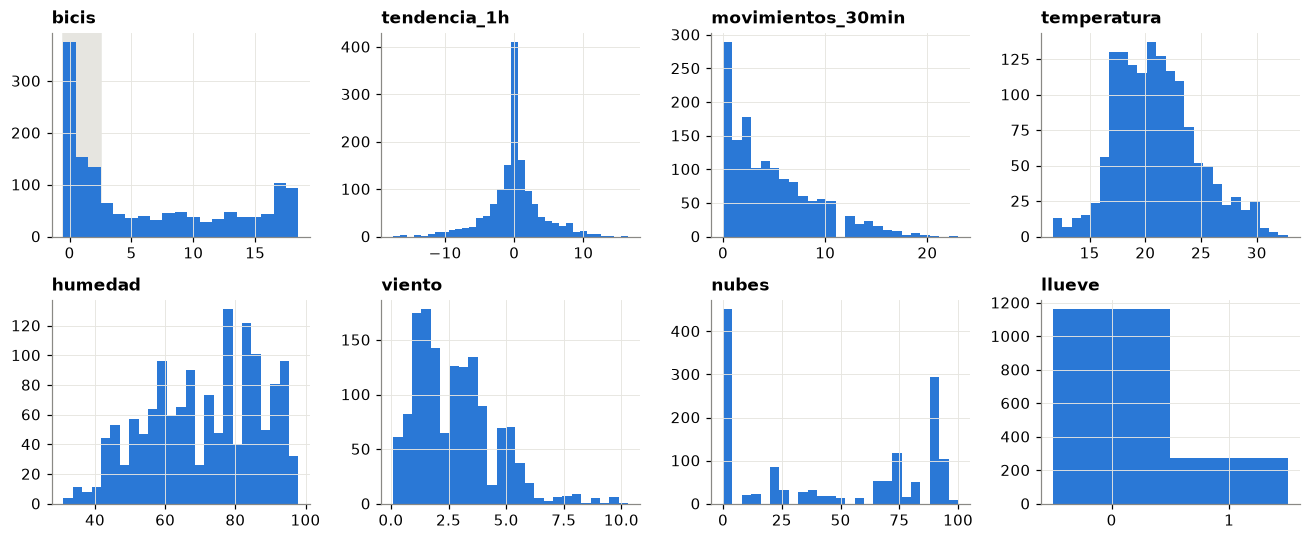

In [ ]:
# Distribución de cada variable en junio (en gris, la zona de alerta: 2 bicis o menos)
BINS = {"bicis": np.arange(-0.5, 19), "tendencia_1h": np.arange(-17.5, 17), "llueve": [-0.5, 0.5, 1.5]}
fig, axes = plt.subplots(2, 4, figsize=(12, 5))
for ax, var in zip(axes.flat, ["bicis", "tendencia_1h", "movimientos_30min", "temperatura",
                               "humedad", "viento", "nubes", "llueve"]):
    ax.hist(f_junio[var].dropna(), bins=BINS.get(var, 25), color=AZUL)
    ax.set_title(var)
axes[0, 0].axvspan(-0.5, UMBRAL_POCAS + 0.5, color=SOMBRA, zorder=0)
axes[1, 3].set_xticks([0, 1])
plt.tight_layout(); plt.show()

- Las bicis tienen una distribución **bimodal**: la estación pasa mucho tiempo vacía o casi vacía (la mitad de las instancias tiene 3 bicis o menos y una cuarta parte ninguna) y otra parte del tiempo llena, cerca de su capacidad de 18 bicis.
- La tendencia de la última hora está centrada en cero, pero hay cambios de hasta 17 bicis en una hora: la estación puede vaciarse o llenarse en muy poco tiempo.
- En junio la temperatura media es de 21 °C y llueve en el 19 % de las instancias.

### 4.2.2 Ciclo diario y semanal: un *drift* recurrente y esperado

Si el uso depende de la hora y del tipo de día, la distribución de los datos cambia varias veces al día y otra vez el fin de semana. Es un cambio previsible y recurrente que hay que caracterizar para no confundirlo después con un drift real.

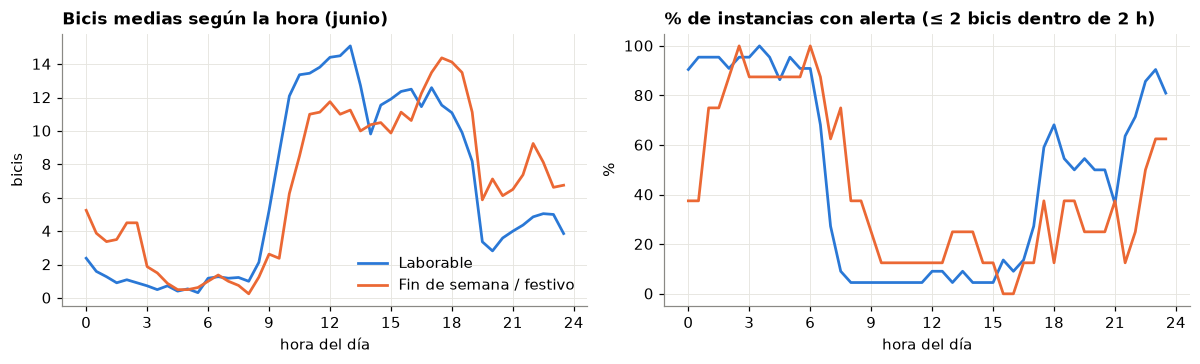

In [ ]:
# Ciclo diario: bicis medias y % de alertas por hora, en laborables y en fines de semana
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharex=True)
for tipo, color in [("Laborable", AZUL), ("Fin de semana / festivo", NARANJA)]:
    g = f_junio[f_junio["tipo_dia"] == tipo].groupby("hora")
    axes[0].plot(g["bicis"].mean(), color=color, lw=1.8, label=tipo)
    axes[1].plot(100 * g["pocas_bicis_2h"].mean(), color=color, lw=1.8, label=tipo)
axes[0].set_title("Bicis medias según la hora (junio)"); axes[0].set_ylabel("bicis")
axes[1].set_title("% de instancias con alerta (≤ 2 bicis dentro de 2 h)"); axes[1].set_ylabel("%")
for ax in axes:
    ax.set_xlabel("hora del día"); ax.set_xticks(range(0, 25, 3))
axes[0].legend(frameon=False)
plt.tight_layout(); plt.show()

- En laborables la estación está casi vacía de madrugada, se llena desde las 8:30 (13-15 bicis de media hacia mediodía) y vuelve a vaciarse a partir de las 19:00. Como la etiqueta mira 2 horas adelante, las alertas superan el 85 % por la noche y casi desaparecen entre las 7:30 y las 17:00.
- En fin de semana el patrón se desplaza: se llena más tarde y las alertas se concentran de madrugada. Con solo 8 días, la curva es más ruidosa.
- Es un cambio recurrente y previsible, no un drift, pero un detector aplicado a las variables tal cual lo confundiría con uno (apartado 4.6).

### 4.2.3 Autocorrelación

Los detectores de drift (ADWIN, KSWIN, DDM…) suponen observaciones independientes. Medimos cuánto se parece cada valor a los anteriores.

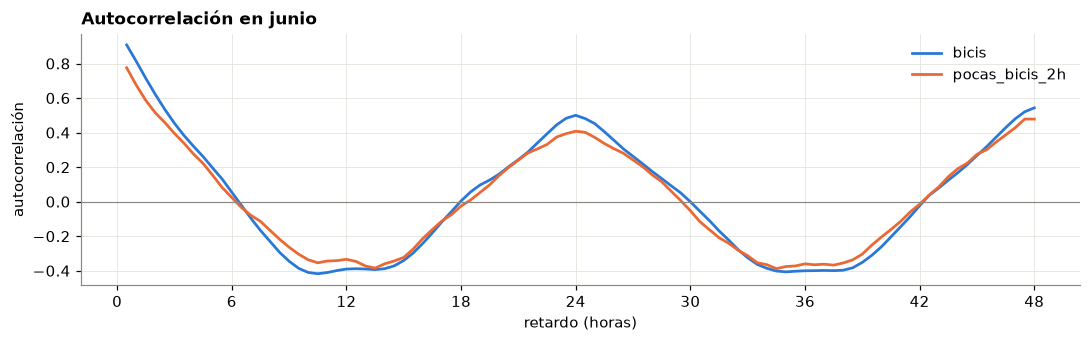

In [ ]:
# Autocorrelación de las bicis y de la etiqueta con retardos de 30 minutos a 2 días (junio)
retardos = np.arange(1, 97)
fig, ax = plt.subplots(figsize=(10, 3.2))
for var, color in [("bicis", AZUL), ("pocas_bicis_2h", NARANJA)]:
    serie = f_junio[var].asfreq(FREQ)
    ax.plot(retardos / 2, [serie.autocorr(k) for k in retardos], color=color, lw=1.8, label=var)
ax.axhline(0, color=GRIS, lw=0.8)
ax.set_xticks(range(0, 49, 6)); ax.set_xlabel("retardo (horas)"); ax.set_ylabel("autocorrelación")
ax.set_title("Autocorrelación en junio"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

- A 30 minutos la autocorrelación es de 0,91 en las bicis y de 0,78 en la etiqueta: el estado actual dice mucho del futuro cercano, así que la **persistencia** será un *baseline* difícil de batir.
- Baja a cero hacia las 6 horas, es negativa a las 12 y vuelve a subir a las 24: es el ciclo diario.
- Las observaciones no son independientes: los errores del modelo llegarán en rachas (apartado 4.5) y, para vigilar los datos, habrá que quitar el ciclo y agregar por día (apartado 4.6).

### 4.2.4 Relación de las variables con la alerta

Antes de elegir un modelo interesa saber si las variables influyen en la alerta cada una por separado o combinándose entre sí. Primero miramos cada variable por separado y después cómo se combinan las dos que más influyen: las bicis actuales y la hora.

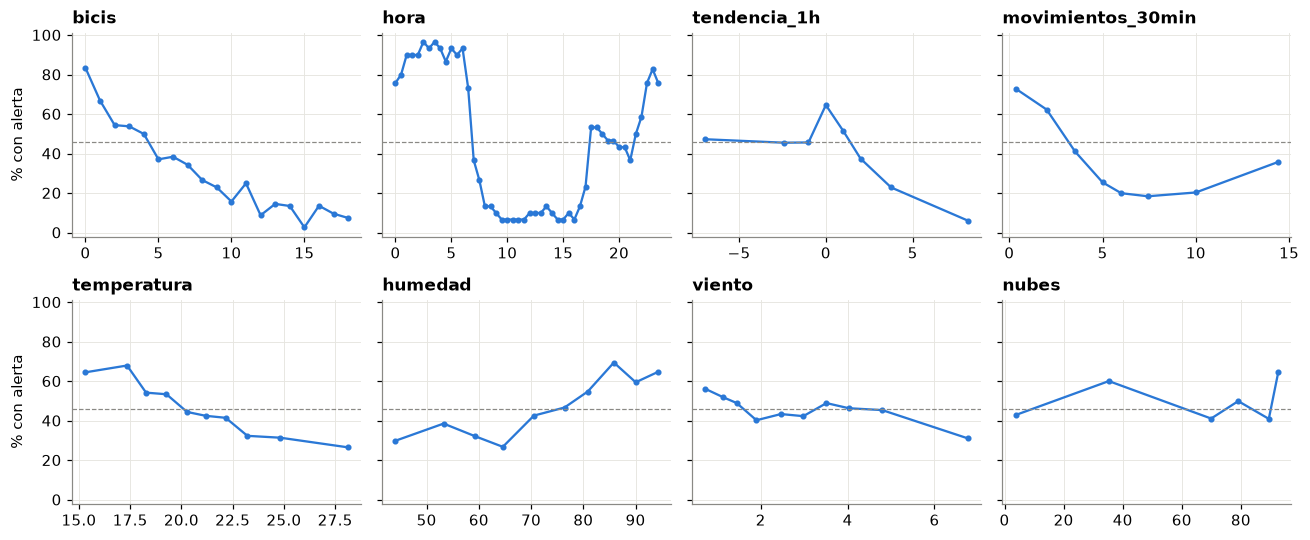

In [ ]:
# % de alerta según el valor de cada variable en junio (la línea discontinua es el % medio de alerta)
fig, axes = plt.subplots(2, 4, figsize=(12, 5), sharey=True)
for ax, var in zip(axes.flat, ["bicis", "hora", "tendencia_1h", "movimientos_30min",
                               "temperatura", "humedad", "viento", "nubes"]):
    valores = f_junio[var]
    tramo = valores if var in ("bicis", "hora") else pd.qcut(valores, 10, duplicates="drop")   # resto: 10 tramos iguales
    g = f_junio.groupby(tramo, observed=True).agg(valor=(var, "mean"), alerta=("pocas_bicis_2h", "mean"))
    ax.plot(g["valor"], 100 * g["alerta"], "o-", color=AZUL, lw=1.5, ms=3)
    ax.axhline(100 * f_junio["pocas_bicis_2h"].mean(), color=GRIS, ls="--", lw=0.8)
    ax.set_title(var)
for ax in axes[:, 0]:
    ax.set_ylabel("% con alerta")
plt.tight_layout(); plt.show()

Acierto de la persistencia en junio: 76.0%


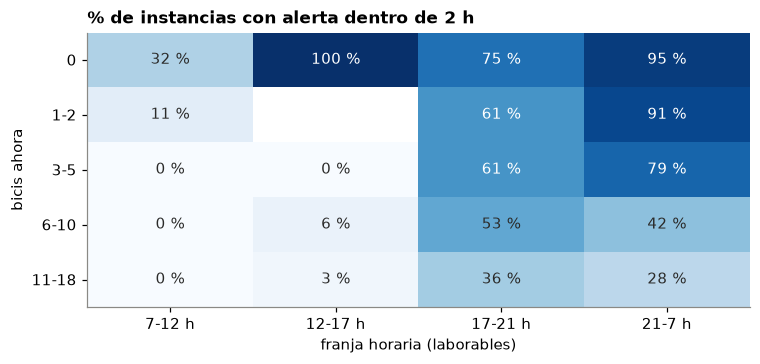

In [ ]:
# % de alerta según las bicis actuales y la franja horaria (laborables de junio); en blanco, grupos con menos de 10 instancias
grupo_bicis = pd.cut(f_junio["bicis"], [-1, 0, 2, 5, 10, 18], labels=["0", "1-2", "3-5", "6-10", "11-18"])
h = f_junio["hora"]
franja = pd.Series(np.select([h < 7, h < 12, h < 17, h < 21], ["21-7 h", "7-12 h", "12-17 h", "17-21 h"], "21-7 h"),
                   index=f_junio.index)
laborable = f_junio["tipo_dia"] == "Laborable"
g = f_junio["pocas_bicis_2h"][laborable].groupby([grupo_bicis[laborable], franja[laborable]], observed=True)
tabla_alerta = (100 * g.mean()).where(g.size() >= 10).unstack()[["7-12 h", "12-17 h", "17-21 h", "21-7 h"]]

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.imshow(tabla_alerta, cmap="Blues", vmin=0, vmax=100, aspect="auto")
for (i, j), v in np.ndenumerate(tabla_alerta.to_numpy()):
    if not np.isnan(v):
        ax.text(j, i, f"{v:.0f} %", ha="center", va="center", color="white" if v > 60 else TINTA)
ax.set_xticks(range(4), tabla_alerta.columns); ax.set_yticks(range(len(tabla_alerta)), tabla_alerta.index)
ax.set_xlabel("franja horaria (laborables)"); ax.set_ylabel("bicis ahora"); ax.grid(False)
ax.set_title("% de instancias con alerta dentro de 2 h")
plt.tight_layout(); plt.show()

persistencia = ((f_junio["bicis"] <= UMBRAL_POCAS) == (f_junio["pocas_bicis_2h"] == 1)).mean()
print(f"Acierto de la persistencia en junio: {persistencia:.1%}")

- Por separado, lo que más se relaciona con la alerta son **las bicis actuales** (más del 80 % de alertas con la estación vacía, menos del 15 % con más de 12 bicis) y **la hora** (más del 85 % de madrugada, menos del 10 % entre las 8:00 y las 16:00). Con pocos movimientos también hay más alertas, porque coinciden con la noche.
- La temperatura y la humedad parecen influir (más alertas con frío y humedad), pero es un efecto de la hora: de noche hace más fresco y hay más humedad. El viento y las nubes apenas cambian el % de alerta.
- Mirar las variables una a una no basta: el efecto de las bicis **depende de la hora**. Con 3 a 5 bicis, la alerta no llega nunca por la mañana ni a mediodía, pero sí en el 61 % de las tardes y el 79 % de las noches. Es una **interacción** que un modelo lineal no recoge con las variables tal cual y que los árboles capturan de forma natural (apartado 4.4).
- La persistencia acierta el 76 % de las instancias de junio: es la referencia mínima que tendrá que superar cualquier modelo.

### 4.2.5 Qué vigilaremos desde julio

Junio no permite ver cómo evolucionará la estación, pero el conocimiento del dominio sí permite anticipar qué cambios conviene vigilar:
- **El uso de la estación**, que puede cambiar con las vacaciones y la vuelta a clase, cuando colegios y universidad se vacían. Si cambia quién usa la estación, también puede cambiar la relación entre las variables y la alerta. Se vigila el error del modelo (*concept drift*, apartado 4.5) y el propio uso, sin etiquetas (*data drift*, apartado 4.6).
- **La temperatura**, que bajará al llegar el otoño. Como en junio el tiempo apenas se relaciona con la alerta más allá de la hora (apartado 4.2.4), no esperamos que afecte al modelo; se comprueba en el apartado 4.6.

## 4.3 Estrategia de aprendizaje y evaluación

### 4.3.1 Evaluación *prequential* con retraso de la etiqueta

En un flujo no hay partición train/test: el modelo **predice cada instancia antes de aprender de ella** (*test-then-train*). Pero aquí **la etiqueta llega 2 horas tarde**: a las 10:00 el sistema predice si a las 12:00 habrá 2 bicis o menos, y solo a las 12:00 sabe si ha acertado. Por eso, cada vez que llega una instancia *x(t)*:
1. **Llegan las etiquetas** de las predicciones hechas hace 2 horas: se comprueba si se acertó, se actualizan las métricas y los detectores de drift, y el modelo aprende de esas instancias.
2. **Se predice** *x(t)*, que queda pendiente hasta *t* + 2 h.

Respetar este retraso es importante: si el modelo aprendiera de la etiqueta en el mismo instante en que predice, estaría usando el futuro y los resultados serían optimistas. Además, como el error se conoce 2 horas tarde, cualquier detección de drift llega como mínimo 2 horas después del cambio.

Nos situamos a **1 de julio de 2016**, cuando el sistema se pone en marcha, y separamos dos fases:
- **Diseño (junio):** el modelo se elige solo con junio. El modelo aprende desde el 1 y se mide desde el 15 (`INICIO_DISENO`), para no evaluar sus primeros días.
- **Despliegue (desde el 1 de julio, `INICIO_EVALUACION`):** el modelo elegido llega habiendo aprendido de junio y funciona online; las métricas y los detectores se evalúan desde ahí.

Métricas: *accuracy* prequential, **F1 de la clase alerta** (la que interesa) y, desde julio, el error diario con su media móvil de 7 días, para ver si el modelo se degrada.

In [ ]:
# Constantes de la evaluación. Los modelos recorren el flujo con flujo_bicis() (apartado 4.1.4) sin esperas (delay=0),
# porque se recorre una vez por modelo y experimento
INICIO_DISENO = pd.Timestamp("2016-06-15")      # fase de diseño (junio): se mide desde el 15, tras 2 semanas de aprendizaje
INICIO_EVALUACION = pd.Timestamp("2016-07-01")  # despliegue: el sistema se pone en marcha el 1 de julio
SEMILLA = 2026                                  # semilla de los modelos y detectores aleatorios (ARF, HAT y KSWIN)
ARBOLES = 25                                    # árboles del Adaptive Random Forest
COLUMNAS_X = ["bicis", "tendencia_1h", "hora", "dia_semana", "es_finde", "es_festivo",
              "temperatura", "humedad", "viento", "nubes", "llueve", "movimientos_30min"]

In [ ]:
# Bucle prequential con la etiqueta retrasada (lo usan todos los experimentos del subsistema 1)
def variables_modelo(x):
    """Variables que recibe el modelo: todas menos el momento, más la hora en forma cíclica (23:30 está cerca de 0:00)."""
    xm = {k: v for k, v in x.items() if k not in ("momento", "hora")}
    xm["hora_sin"] = math.sin(2 * math.pi * x["hora"] / 24)
    xm["hora_cos"] = math.cos(2 * math.pi * x["hora"] / 24)
    return xm


def solo_junio(instancias):
    """Corta el flujo el 1 de julio: en la fase de diseño solo conocemos los datos de junio."""
    return takewhile(lambda par: par[0]["momento"] < INICIO_EVALUACION, instancias)


def prequential(modelo, instancias, retraso=HORIZONTE, detectores=None, congelar_desde=None):
    """Evaluación test-then-train con la etiqueta retrasada `retraso`.
    detectores: dict nombre -> detector de River, que recibe el bit de error (1 = fallo).
    congelar_desde: a partir de esa fecha el modelo deja de aprender (para el experimento del apartado 4.5).
    Devuelve (registro, detecciones): el registro tiene una fila por predicción evaluada (momento de la predicción,
    momento en que llega la etiqueta, etiqueta, predicción y bit de error); detecciones, las fechas de cada detector."""
    retraso = pd.Timedelta(retraso)
    detectores = detectores or {}
    pendientes = collections.deque()
    registros, detecciones = [], {nombre: [] for nombre in detectores}
    for x, y in instancias:
        t = x["momento"]
        # 1) Llegan las etiquetas de las predicciones hechas hace `retraso`
        while pendientes and pendientes[0][0] + retraso <= t:
            t0, x0, y0, p0 = pendientes.popleft()
            error = int(p0 != y0)
            registros.append((t0, t, y0, p0, error))
            for nombre, det in detectores.items():
                det.update(error)
                if det.drift_detected:
                    detecciones[nombre].append(t)
            if congelar_desde is None or t < congelar_desde:
                modelo.learn_one(x0, y0)
        # 2) Llega x(t): se predice y queda pendiente
        xm = variables_modelo(x)
        p = modelo.predict_one(xm)
        pendientes.append((t, xm, y, bool(p) if p is not None else False))
    registro = pd.DataFrame(registros, columns=["momento", "revelada", "y", "y_pred", "error"]).set_index("momento")
    return registro, detecciones


def resumen(registro, desde=None):
    """Accuracy y F1 de la alerta de las predicciones hechas desde `desde` (por defecto, todas)."""
    if desde is not None:
        registro = registro[registro.index >= desde]
    acc, f1 = metrics.Accuracy(), metrics.F1()
    for y, p in zip(registro["y"], registro["y_pred"]):
        acc.update(y, p)
        f1.update(y, p)
    return {"accuracy_%": round(100 * acc.get(), 1), "F1_alerta_%": round(100 * f1.get(), 1)}

### 4.3.2 *Baselines*

Un modelo solo tiene sentido si mejora lo que se consigue sin aprender nada:
- **Clase mayoritaria:** predice siempre la clase más frecuente vista hasta el momento.
- **Persistencia:** "si ahora hay 2 bicis o menos, dentro de 2 horas también". Es el *baseline* natural en series temporales y aquí es muy exigente, porque el estado de la estación cambia despacio.

In [ ]:
# Baselines sin aprendizaje, con la misma interfaz que un modelo de River (predict_one / learn_one)
class ClaseMayoritaria:
    def __init__(self):
        self.conteo = collections.Counter()
    def predict_one(self, x):
        return self.conteo.most_common(1)[0][0] if self.conteo else None
    def learn_one(self, x, y):
        self.conteo[y] += 1


class Persistencia:
    def predict_one(self, x):
        return x["bicis"] <= UMBRAL_POCAS
    def learn_one(self, x, y):
        pass

## 4.4 Elección razonada del modelo de alerta

El modelo es una decisión de diseño, así que se elige **solo con junio**: los modelos aprenden desde el 1 y se miden del 15 al 30 (`INICIO_DISENO`). Junio es un periodo estable, así que la comparación mide la precisión de cada modelo, pero **no** su capacidad de adaptarse a un drift: esa parte se razona aquí y se comprueba en el análisis retrospectivo.

**Qué exige el problema:**

| Característica del problema | Característica que buscamos en el modelo |
|---|---|
| La probabilidad de quedarse sin bicis depende de **interacciones** entre variables: la misma hora significa cosas distintas con 3 bicis que con 15, y en laborable que en fin de semana (apartado 4.2.4) | capturar relaciones **no lineales** con interacciones entre variables |
| El uso puede cambiar con las vacaciones y la vuelta a clase (apartado 4.2.5), y con él la relación entre las variables y la alerta | **adaptarse** a los cambios sin intervención |
| Hay ruido: días de lluvia, festivos y días atípicos | **estabilidad**: que una racha rara no cambie mucho el modelo |
| La alerta alimenta una decisión con costes (reponer bicis o no) | dar **probabilidades**, no solo la clase, para poder ajustar el umbral |

**Candidato: el *Adaptive Random Forest* (ARF) [4].** Cumple los cuatro requisitos: sus árboles capturan las interacciones, cada árbol tiene un detector ADWIN que lo sustituye si empeora, promediar 25 árboles da estabilidad y la votación da una probabilidad.

Lo comparamos con los *baselines* (apartado 4.3.2) y con un modelo por cada parte del razonamiento:
- **Hoeffding Tree:** un solo árbol que no se adapta. Si iguala al ARF, el ensemble no aporta.
- **Hoeffding Adaptive Tree:** un solo árbol que se adapta (un ADWIN en cada nodo). Si iguala al ARF, basta con adaptarse, sin ensemble.
- **Regresión logística** (lineal en el log-odds): si iguala a los árboles, las interacciones no importan.

Descartamos de entrada Gaussian Naive Bayes, porque supone variables independientes y aquí `bicis`, `tendencia_1h` y la hora están muy relacionadas, y el perceptrón, porque no da probabilidades. El *Extremely Fast Decision Tree* da en junio exactamente lo mismo que el Hoeffding Tree: con un mes de datos no llega a reevaluar ninguna división.

                         ms/instancia  memoria (MB)
Hoeffding Tree                   0.03          0.24
Hoeffding Adaptive Tree          0.04          0.25
ARF (25 árboles)                 0.71         17.15
Regresión logística              0.02          0.00


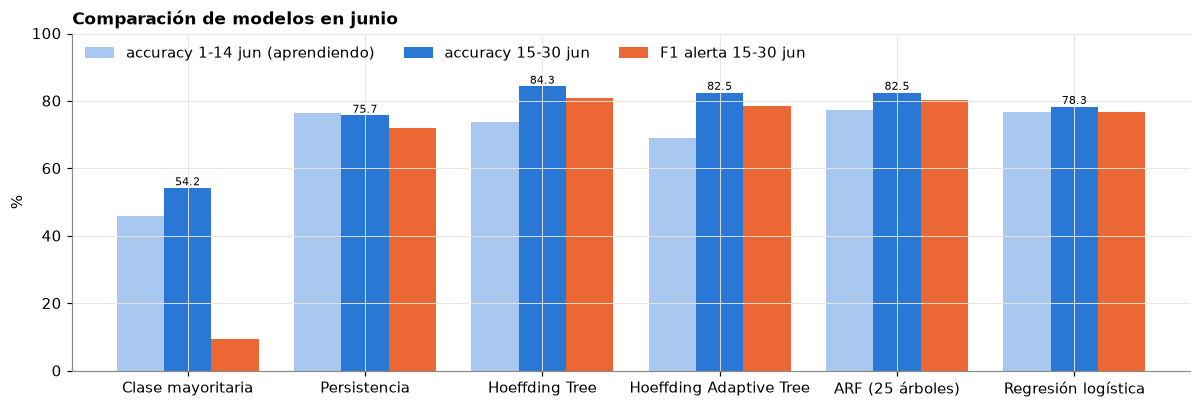

In [ ]:
# Comparación de modelos (fase de diseño, solo junio): baselines, Hoeffding Tree, Hoeffding Adaptive Tree, ARF y regresión logística
MODELOS = {
    "Clase mayoritaria": ClaseMayoritaria,
    "Persistencia": Persistencia,
    "Hoeffding Tree": lambda: tree.HoeffdingTreeClassifier(),
    "Hoeffding Adaptive Tree": lambda: tree.HoeffdingAdaptiveTreeClassifier(seed=SEMILLA),
    "ARF (25 árboles)": lambda: forest.ARFClassifier(n_models=ARBOLES, seed=SEMILLA),
    "Regresión logística": lambda: preprocessing.StandardScaler() | linear_model.LogisticRegression(),
}

def memoria_kb(modelo):
    """Memoria que ocupa el modelo de River al final del flujo (los baselines propios no la miden)."""
    return round(modelo._raw_memory_usage / 1024, 1) if hasattr(modelo, "_raw_memory_usage") else np.nan


filas = {}
for nombre, fab in MODELOS.items():
    t0 = time.time()
    modelo = fab()
    r, _ = prequential(modelo, solo_junio(flujo_bicis()))
    segundos = time.time() - t0
    res = resumen(r, desde=INICIO_DISENO)
    filas[nombre] = {"accuracy 1-14 jun (aprendiendo)": round(100 * (1 - r["error"][:INICIO_DISENO - pd.Timedelta("1min")].mean()), 1),
                     "accuracy 15-30 jun": res["accuracy_%"], "F1 alerta 15-30 jun": res["F1_alerta_%"],
                     "ms/instancia": round(1000 * segundos / len(r), 2), "memoria (MB)": round(memoria_kb(modelo) / 1024, 2)}
tabla_modelos = pd.DataFrame(filas).T

ax = tabla_modelos.iloc[:, :3].plot.bar(color=["#a9c8ef", AZUL, NARANJA], figsize=(11, 3.8), rot=0, width=0.8)
ax.bar_label(ax.containers[1], fmt="%.1f", fontsize=7.5)
ax.set_ylim(0, 100); ax.set_ylabel("%"); ax.set_title("Comparación de modelos en junio")
ax.legend(frameon=False, ncol=3, loc="upper left")
plt.tight_layout(); plt.show()
print(tabla_modelos.iloc[2:, 3:].to_string())

- Los tres modelos de árboles superan con claridad a los *baselines* (persistencia 75,7 %, clase mayoritaria 54,2 %) y a la regresión logística (78,3 %): las interacciones importan.
- En junio gana el **Hoeffding Tree**, tanto en *accuracy* (84,3 %) como en F1 (80,8 %). El ARF y el Hoeffding Adaptive Tree empatan en *accuracy* (82,5 %), pero el ARF detecta mejor la alerta (F1 80,4 % frente a 78,6 %) y aprende antes (77,3 % en las dos primeras semanas frente a 68,9 %). Con un solo mes de datos pesa que cada árbol del ARF vea solo una parte de los datos y de las variables.
- **Aun así, elegimos el ARF**: junio no tiene cambios y desde julio puede haberlos. El Hoeffding Tree no revisa sus divisiones una vez hechas; el ARF sustituye los árboles que empeoran y, al promediar 25, su error es más estable. Lo comprobamos en el análisis retrospectivo, comparando los cuatro modelos de julio a octubre y ante un cambio fuerte (apartado 4.7).
- El precio es el coste: el ARF ocupa unos 17 MB frente a 0,25 MB de un solo árbol y tarda unas 25 veces más por instancia (0,7 ms frente a 0,03 ms). Para una estación da igual; para toda la red habría que tenerlo en cuenta.

### **Análisis retrospectivo**

Hasta el apartado 4.4 nos hemos situado a 1 de julio y hemos tomado las decisiones de diseño solo con junio. Ahora el sistema ya ha funcionado online de julio a octubre: analizamos lo que ha ocurrido y comparamos alternativas con información que en julio no teníamos.

**Cómo se evalúa el drift en un flujo real.** No sabemos dónde hay un drift de verdad, así que:
- Las alarmas se comparan con **eventos conocidos** del calendario de Toulouse en 2016: vacaciones escolares (desde el 2 de julio), festivos (14 de julio y 15 de agosto), vuelta a clase (1 de septiembre) y la bajada de temperatura de mediados de septiembre.
- Solo se cuentan las alarmas **desde el 1 de julio**: en junio el modelo aún está aprendiendo y su error no debe confundirse con un drift.
- Las alarmas se fechan cuando el sistema puede verlas (al llegar la etiqueta), no en el momento de la predicción.

In [ ]:
# Eventos del calendario y función para dibujar una señal y las detecciones de cada detector
VACACIONES = (pd.Timestamp("2016-07-02"), pd.Timestamp("2016-08-31"))
EVENTOS = {"2 jul: vacaciones escolares": "2016-07-02", "14 jul: festivo": "2016-07-14", "15 ago: festivo": "2016-08-15",
           "1 sep: vuelta a clase": "2016-09-01"}
EVENTOS = {k: pd.Timestamp(v) for k, v in EVENTOS.items()}


def dibujar_detecciones(senal, detecciones, titulo, ylabel, desde=None, suavizada=None, cambio=None):
    """Arriba la señal vigilada (y, si se da, una versión suavizada); abajo una fila por detector con sus detecciones ( | ).
    cambio: fecha de un cambio conocido, que se marca con una línea roja (apartado 4.7)."""
    nombres = list(detecciones)
    fig, (a1, a2) = plt.subplots(2, 1, sharex=True, figsize=(11, 2.8 + 0.32 * len(nombres)),
                                 gridspec_kw={"height_ratios": [2.4, 0.32 * len(nombres) + 0.3], "hspace": 0.08})
    if suavizada is None:
        a1.plot(senal.index, senal.values, color=AZUL, lw=1.4)
    else:
        a1.plot(senal.index, senal.values, color=AZUL, lw=1, alpha=0.45, label="diario")
        a1.plot(suavizada.index, suavizada.values, color=AZUL, lw=2.2, label="media móvil de 7 días")
        a1.legend(frameon=False, loc="upper right", ncol=2)
    for ax in (a1, a2):
        ax.axvspan(*VACACIONES, color=SOMBRA, lw=0, zorder=0)
        for nombre, fecha in EVENTOS.items():
            ax.axvline(fecha, color=GRIS, ls=":", lw=1)
        if desde is not None:
            ax.axvspan(senal.index.min(), desde, color="#f4f3ef", lw=0, zorder=0)
        if cambio is not None:
            ax.axvline(cambio, color=ROJO, lw=1.2)
    a1.text(VACACIONES[0] + pd.Timedelta(days=1), a1.get_ylim()[1], "vacaciones escolares", va="top", color=TINTA, fontsize=8.5)
    for j, nombre in enumerate(nombres):
        fechas = [d for d in detecciones[nombre] if desde is None or d >= desde]
        a2.scatter(fechas, [j] * len(fechas), marker="|", s=180, lw=2, color=TINTA)
    a2.set_yticks(range(len(nombres)))
    a2.set_yticklabels([f"{n} ({len([d for d in detecciones[n] if desde is None or d >= desde])})" for n in nombres])
    a2.set_ylim(len(nombres) - 0.5, -0.5)
    a2.grid(axis="y", visible=False)
    a1.set_title(titulo)
    a1.set_ylabel(ylabel)
    plt.show()

## 4.5 El modelo en el flujo real: rendimiento y *concept drift*

### 4.5.1 ¿Se sostiene la elección del ARF?

En junio ganaba el Hoeffding Tree (apartado 4.4), pero elegimos el ARF pensando en los cambios que podían llegar desde julio. Ahora que el sistema ha funcionado de julio a octubre, comparamos los cuatro modelos y la persistencia sobre todo el flujo, midiendo desde el 1 de julio.

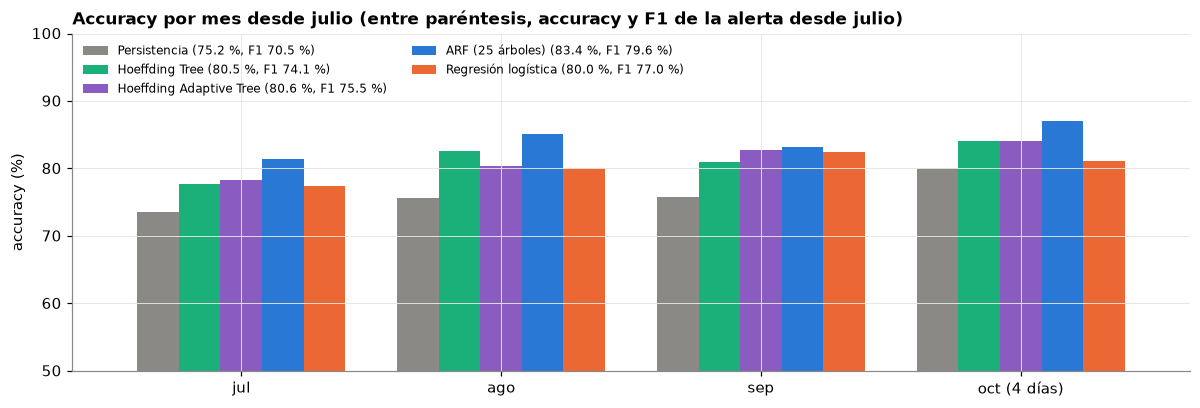

In [ ]:
# Los cuatro modelos del apartado 4.4 y la persistencia sobre todo el flujo, medidos desde julio
NOMBRES_FLUJO = ["Persistencia", "Hoeffding Tree", "Hoeffding Adaptive Tree", "ARF (25 árboles)", "Regresión logística"]
modelos_flujo, registros_flujo = {}, {}
for nombre in NOMBRES_FLUJO:
    modelos_flujo[nombre] = MODELOS[nombre]()
    registros_flujo[nombre], _ = prequential(modelos_flujo[nombre], flujo_bicis())
arf, reg_arf = modelos_flujo["ARF (25 árboles)"], registros_flujo["ARF (25 árboles)"]   # el modelo del sistema

total = {n: resumen(r, desde=INICIO_EVALUACION) for n, r in registros_flujo.items()}
acc_mes = pd.DataFrame({f"{n} ({total[n]['accuracy_%']} %, F1 {total[n]['F1_alerta_%']} %)":
                        100 * (1 - r["error"][INICIO_EVALUACION:].resample("MS").mean()) for n, r in registros_flujo.items()})
acc_mes.index = ["jul", "ago", "sep", "oct (4 días)"]
ax = acc_mes.plot.bar(color=[GRIS, VERDE, MORADO, AZUL, NARANJA], figsize=(11, 3.8), rot=0, width=0.8)
ax.set_ylim(50, 100); ax.set_ylabel("accuracy (%)")
ax.set_title("Accuracy por mes desde julio (entre paréntesis, accuracy y F1 de la alerta desde julio)")
ax.legend(frameon=False, ncol=2, loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

- Desde julio **el ARF es el mejor modelo** (83,4 % de *accuracy* y 79,6 % de F1) y lo es todos los meses. El Hoeffding Tree, que ganaba en junio, baja al 80,5 % (F1 74,1 %): sin poder revisar sus divisiones, queda casi al nivel de la regresión logística (80,0 %).
- El Hoeffding Adaptive Tree (80,6 %) apenas mejora al Hoeffding Tree: adaptarse con un solo árbol no basta; lo que aporta es combinar 25 árboles que se renuevan.
- Todos superan a la persistencia (75,2 %) todos los meses. **La elección del ARF hecha con junio se sostiene** (octubre solo tiene 4 días).

### 4.5.2 ¿Qué variables usa el ARF?

Al final del flujo miramos por qué variables dividen los nodos de los 25 árboles del ARF (la hora entra en el modelo como seno y coseno, que se cuentan juntos). Después entrenamos el mismo ARF **sin ninguna variable meteorológica** (temperatura, humedad, viento, nubes y lluvia) para ver si las echa de menos.

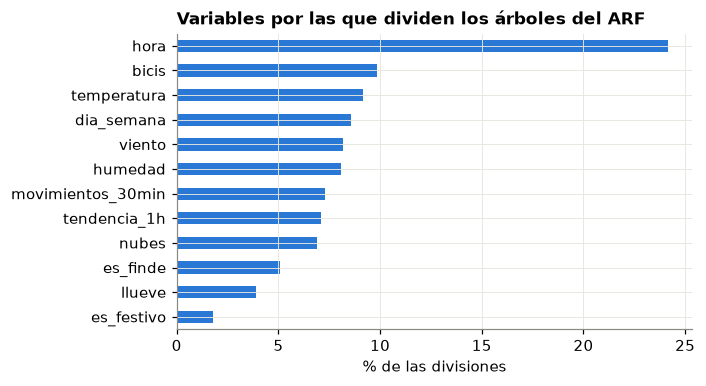

In [ ]:
# Variables que usa el ARF al final del flujo: % de los nodos de sus 25 árboles que dividen por cada variable
divisiones = pd.concat([arbol.to_dataframe()["feature"] for arbol in arf.models]).dropna()
divisiones = divisiones.replace({"hora_sin": "hora", "hora_cos": "hora"}).value_counts(normalize=True).mul(100)
ax = divisiones.sort_values().plot.barh(color=AZUL, figsize=(6.5, 3.6))
ax.set_xlabel("% de las divisiones"); ax.set_ylabel(""); ax.set_title("Variables por las que dividen los árboles del ARF")
plt.tight_layout(); plt.show()

In [ ]:
# El mismo ARF online, pero sin las variables meteorológicas
class SinVariables:
    """Envuelve un modelo y le oculta algunas variables."""
    def __init__(self, modelo, quitar):
        self.modelo, self.quitar = modelo, set(quitar)
    def predict_one(self, x):
        return self.modelo.predict_one({k: v for k, v in x.items() if k not in self.quitar})
    def learn_one(self, x, y):
        self.modelo.learn_one({k: v for k, v in x.items() if k not in self.quitar}, y)


METEOROLOGICAS = ["temperatura", "humedad", "viento", "nubes", "llueve"]
reg_sin_meteo, _ = prequential(SinVariables(forest.ARFClassifier(n_models=ARBOLES, seed=SEMILLA), METEOROLOGICAS), flujo_bicis())

print(f"Error desde julio: ARF {100 * reg_arf['error'][INICIO_EVALUACION:].mean():.1f} %, "
      f"ARF sin variables meteorológicas {100 * reg_sin_meteo['error'][INICIO_EVALUACION:].mean():.1f} %")

Error desde julio: ARF 16.6 %, ARF sin variables meteorológicas 15.8 %


- La **hora** es con diferencia la variable más usada (24 % de las divisiones), seguida de las **bicis actuales** (10 %): es lo que anticipaba el exploratorio (apartado 4.2.4). El resto se reparte de forma parecida, entre el 2 % y el 9 %.
- Las variables meteorológicas aparecen en las divisiones (la temperatura en el 9 %, el viento en el 8 %), pero eso no quiere decir que sirvan: en cada división cada árbol elige entre unas pocas variables al azar, y a veces solo puede elegir entre variables poco útiles.
- La prueba directa lo aclara: **sin ninguna variable meteorológica, el ARF falla incluso algo menos** desde julio (15,8 % frente a 16,6 %). El tiempo no aporta al modelo.

### 4.5.3 Detectores de *concept drift*

Un detector de *concept drift* vigila el **bit de error** del modelo (1 = fallo), que se conoce 2 horas después, y avisa cuando el modelo deja de acertar como antes. Buscamos cambios de días o semanas (vacaciones, vuelta a clase), así que elegimos los detectores y sus parámetros para esa escala y los fijamos a priori:

| Detector | Parámetros | Por qué |
|---|---|---|
| **HDDM_W** | `lambda_val=0,02` | Media del error en la que pesa más lo reciente; recuerda unas 1/0,02 = 50 predicciones (un día). Con el valor por defecto (0,05) recordaría unas 10 horas, y una mala noche bastaría para hacerlo saltar |
| **Page-Hinkley** | `mode="up"`, `threshold=15` | Suma cuánto se pasa el error de su media; solo interesan las subidas. Con `threshold=15`, una subida del error de 5 puntos tiene que mantenerse una semana para dar la alarma (con el valor por defecto, 50, más de tres) |
| **ADWIN** | `delta=0,05`, `clock=48` | Ventana adaptativa que compara la media de su parte antigua y de su parte reciente una vez al día, con el nivel de significación habitual. Detecta subidas y bajadas |

Descartamos **DDM**, porque HDDM_W vigila lo mismo con una base estadística más sólida y DDM es poco sensible a cambios graduales; **EDDM**, porque mide la distancia entre errores consecutivos y aquí los errores llegan en rachas (la etiqueta tiene una autocorrelación de 0,78 a 30 minutos, apartado 4.2.3); y **HDDM_A**, porque de la familia HDDM nos quedamos con la versión ponderada.

HDDM_W        4 drifts: 17-07, 14-08, 14-09, 26-09  (10 zonas de warning)
Page-Hinkley  5 drifts: 03-07, 14-08, 11-09, 26-09, 03-10
ADWIN         1 drifts: 01-09


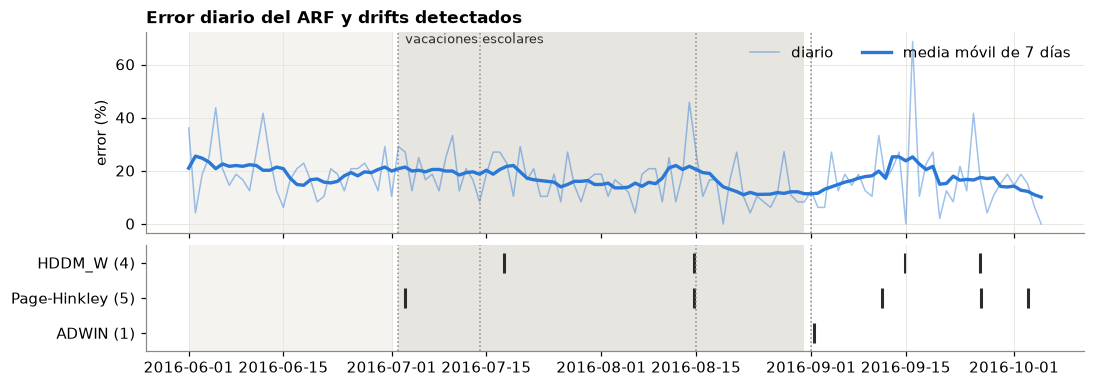

In [ ]:
# Los tres detectores sobre los errores del ARF, en el orden en que se conocen las etiquetas (se cuentan desde julio)
def vigilar(detector, serie, desde=INICIO_EVALUACION):
    """Pasa por el detector una serie de pares (momento, valor) (el bit de error, o una variable en el apartado 4.6)
    y devuelve las fechas de sus zonas de warning y de sus drifts desde `desde`."""
    en_warning, avisos, drifts = False, [], []
    for t, valor in serie:
        detector.update(valor)
        if t < desde:                  # aprendizaje inicial: no se cuenta
            continue
        if detector.drift_detected:
            drifts.append(t)
            en_warning = False
        elif getattr(detector, "warning_detected", False):   # solo los detectores binarios tienen zona de warning
            if not en_warning:
                avisos.append(t)
            en_warning = True
        else:
            en_warning = False
    return avisos, drifts


errores = list(zip(reg_arf["revelada"], reg_arf["error"]))
DETECTORES = {"HDDM_W": drift.binary.HDDMW(lambda_val=0.02),   # en River 0.26 la clase se llama HDDMW
              "Page-Hinkley": drift.PageHinkley(mode="up", threshold=15),
              "ADWIN": drift.ADWIN(delta=0.05, clock=48)}
detecciones_arf = {}
for nombre, detector in DETECTORES.items():
    avisos, detecciones_arf[nombre] = vigilar(detector, errores)
    fechas = ", ".join(t.strftime("%d-%m") for t in detecciones_arf[nombre])
    print(f"{nombre:13s} {len(detecciones_arf[nombre])} drifts: {fechas}" + (f"  ({len(avisos)} zonas de warning)" if avisos else ""))

error_diario = reg_arf["error"].resample("D").mean()
dibujar_detecciones(100 * error_diario, detecciones_arf, "Error diario del ARF y drifts detectados", "error (%)",
                    desde=INICIO_EVALUACION, suavizada=100 * error_diario.rolling(7, center=True, min_periods=4).mean())

- Cada detector da sus alarmas en fechas distintas, y una alarma solo dice que su estadístico ha superado el umbral, no que haya *concept drift*. La media móvil del error no da ningún salto sostenido: sube y baja algunas semanas.
- HDDM_W y Page-Hinkley coinciden a **mediados de agosto** (el 14, la semana del festivo) y a **finales de septiembre** (el 26). ADWIN salta una sola vez, el 1 de septiembre, y lo hace porque el error **baja**. A continuación comprobamos si detrás de esas coincidencias hay un cambio real.

### 4.5.4 ¿Hay *concept drift* de verdad? Modelo congelado

Una alarma hay que comprobarla. Congelamos el ARF (deja de aprender) el **15 de agosto**, justo después de la primera coincidencia de HDDM_W y Page-Hinkley, y lo comparamos con el que sigue aprendiendo; hasta ese día son idénticos. Si después el congelado falla igual, lo aprendido sigue valiendo y la alarma fue transitoria; si falla más de forma sostenida, la relación entre las variables y la alerta ha cambiado.

Desde que se congela: error online 15.1 %, congelado 15.6 %; el congelado falla más en 5 de 8 semanas
Desde el 26 de septiembre: online 13.0 %, congelado 15.8 %


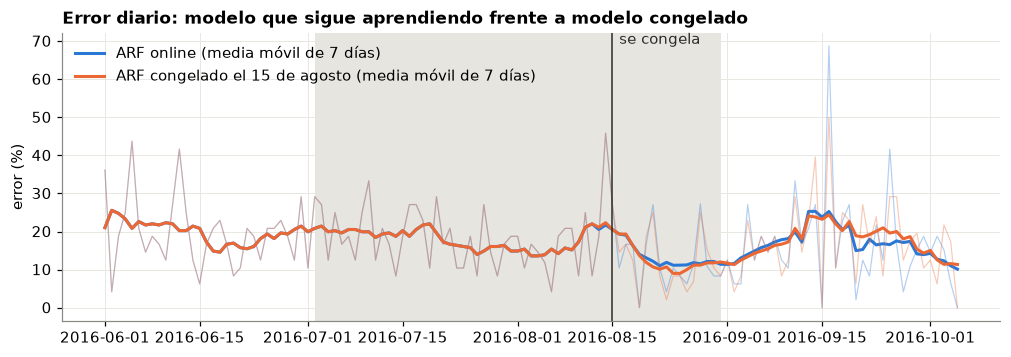

In [ ]:
# ARF congelado el 15 de agosto frente al ARF que sigue aprendiendo: error diario y su media móvil de 7 días
CONGELAR = pd.Timestamp("2016-08-15")
reg_congelado, _ = prequential(forest.ARFClassifier(n_models=ARBOLES, seed=SEMILLA), flujo_bicis(), congelar_desde=CONGELAR)
diferencia_semanal = (reg_congelado["error"] - reg_arf["error"])[CONGELAR:].resample("W-SUN").mean()
print(f"Desde que se congela: error online {100 * reg_arf['error'][CONGELAR:].mean():.1f} %, "
      f"congelado {100 * reg_congelado['error'][CONGELAR:].mean():.1f} %; "
      f"el congelado falla más en {(diferencia_semanal > 0).sum()} de {len(diferencia_semanal)} semanas")
FINAL = pd.Timestamp("2016-09-26")
print(f"Desde el 26 de septiembre: online {100 * reg_arf['error'][FINAL:].mean():.1f} %, "
      f"congelado {100 * reg_congelado['error'][FINAL:].mean():.1f} %")

fig, ax = plt.subplots(figsize=(11, 3.4))
for reg, nombre, color in [(reg_arf, "ARF online", AZUL), (reg_congelado, "ARF congelado el 15 de agosto", NARANJA)]:
    diario = 100 * reg["error"].resample("D").mean()
    ax.plot(diario.index, diario.values, color=color, lw=0.8, alpha=0.35)
    ax.plot(diario.index, diario.rolling(7, center=True, min_periods=4).mean(), color=color, lw=2, label=f"{nombre} (media móvil de 7 días)")
ax.axvline(CONGELAR, color=TINTA, lw=1)
ax.text(CONGELAR + pd.Timedelta(days=1), ax.get_ylim()[1], "se congela", va="top", color=TINTA)
ax.axvspan(*VACACIONES, color=SOMBRA, lw=0, zorder=0)
ax.set_title("Error diario: modelo que sigue aprendiendo frente a modelo congelado"); ax.set_ylabel("error (%)")
ax.legend(frameon=False, loc="upper left")
plt.show()

- Tras la alarma del 14 de agosto, el congelado falla igual o menos que el online durante tres semanas: la alarma respondía a una semana atípica (el festivo), no a un cambio de concepto.
- Desde mediados de septiembre el congelado se queda algo atrás (algo más de un punto por semana) y, desde el 26, justo la segunda coincidencia de HDDM_W y Page-Hinkley, la diferencia crece (15,8 % de error frente al 13,0 %). Puede ser el primer *concept drift* real del periodo, pero son solo diez días antes de que acabe el flujo y no se puede confirmar.
- En conjunto, el *concept drift* de este flujo es leve y el aprendizaje online lo absorbe (el ARF ya lleva un ADWIN en cada árbol): un detector externo que dispare reentrenamientos aportaría poco.

## 4.6 *Data drift* en el flujo real: ¿cambian los datos que llegan?

Los detectores de *data drift* no necesitan la etiqueta: vigilan directamente las variables de entrada y avisan si cambia su distribución. Vigilamos las dos variables que anticipaba el apartado 4.2.5:
- **El uso de la estación** (`movimientos_30min`, las bicis que entran o salen en cada media hora), que puede cambiar con las vacaciones y la vuelta a clase.
- **La temperatura**, la variable meteorológica que cambia de forma sostenida del verano al otoño. La lluvia, en cambio, aparece en días sueltos, no como un cambio que se mantenga.

Con el mismo flujo diario, el apartado 4.6.3 agrupa además los días por tipo, para marcar los días atípicos y saber cuándo es menos fiable la alerta.

### 4.6.1 Preparación de las señales

Los detectores suponen observaciones independientes, y estas variables tienen un ciclo diario y semanal muy marcado (apartados 4.2.2 y 4.2.3): aplicados tal cual, confundirían el paso de la noche al día con un cambio. Por eso:
- **Desestacionalizamos online el uso:** a cada valor le restamos la media de su misma franja horaria y tipo de día, calculada solo con los datos que ya han llegado. El resultado es una **anomalía**: cuánto se aparta el uso de lo normal para ese momento. Sin ella, los fines de semana parecerían bajadas del uso.
- **Agregamos por día:** los cambios que buscamos duran días o semanas, así que el detector recibe un valor al día: la anomalía media del uso y la temperatura media (la media diaria ya quita el ciclo diario de la temperatura). En las gráficas se dibuja el uso real, en movimientos al día.

In [ ]:
# Señales diarias: anomalía del uso (desestacionalizada online) y temperatura media
MIN_OBS = 4             # observaciones de una franja antes de empezar a calcular su anomalía
MIN_MEDIAS_HORAS = 40   # un día se usa si tiene al menos 40 de sus 48 medias horas

medias = collections.defaultdict(stats.Mean)
filas = []
for x, y in flujo_bicis():
    t = x["momento"]
    tipo = "finde" if x["es_finde"] or x["es_festivo"] else "laborable"
    m = medias[(t.hour * 2 + t.minute // 30, tipo)]
    # anomalía negativa = la estación se usa menos de lo habitual en esa franja (no que pierda bicis)
    anomalia = x["movimientos_30min"] - m.get() if m.n >= MIN_OBS else np.nan
    m.update(x["movimientos_30min"])
    filas.append({"momento": t, "uso_anomalia": anomalia, "movimientos": x["movimientos_30min"], "temperatura": x["temperatura"]})
senales = pd.DataFrame(filas).set_index("momento")

completos = senales["temperatura"].resample("D").count() >= MIN_MEDIAS_HORAS
diarias = senales.resample("D").mean()[completos].dropna()
diarias["movimientos_dia"] = 48 * diarias.pop("movimientos")   # uso real: movimientos al día (solo para las gráficas)
SD_JUNIO = diarias[:FIN_CALIBRACION].std()   # desviación típica de cada señal en junio, para fijar Page-Hinkley
print(f"Días: {len(diarias)} | desviación típica en junio: uso {SD_JUNIO['uso_anomalia']:.2f} movimientos/30 min, "
      f"temperatura {SD_JUNIO['temperatura']:.2f} °C")

Días: 116 | desviación típica en junio: uso 0.93 movimientos/30 min, temperatura 2.12 °C


### 4.6.2 Detección

Los parámetros se fijan a priori para una señal diaria y cambios que duran días o semanas. Los detectores reciben las señales desde junio, pero solo se cuentan las alarmas desde el 1 de julio.

| Detector | Parámetros | Por qué |
|---|---|---|
| **KSWIN** | `window_size=28`, `stat_size=14`, `alpha=0,05` | Compara la distribución de las dos últimas semanas con la de las dos anteriores: con semanas completas, el ciclo semanal no se confunde con un cambio |
| **ADWIN** | `delta=0,05`, `clock=1`, `min_window_length=7` | Compara medias cada día (por defecto, cada 32 observaciones: unas 4 veces en todo el periodo), con al menos una semana a cada lado del corte |
| **Page-Hinkley** | `delta=0,5·sd`, `threshold=3·sd`, `min_instances=7`, `mode="both"` | Sus parámetros están en unidades de la señal, así que se expresan en desviaciones típicas de junio (sd): un cambio sostenido de una desviación típica lo hace saltar en unos 6 días |

In [ ]:
# Detectores de data drift sobre las señales diarias (parámetros fijados a priori)
def detectores_datos(sd):
    return {"KSWIN": drift.KSWIN(alpha=0.05, window_size=28, stat_size=14, seed=SEMILLA),
            "ADWIN": drift.ADWIN(delta=0.05, clock=1, min_window_length=7),
            "Page-Hinkley": drift.PageHinkley(delta=0.5 * sd, threshold=3 * sd, min_instances=7, mode="both")}


alarmas = {col: {nombre: vigilar(det, diarias[col].items())[1] for nombre, det in detectores_datos(SD_JUNIO[col]).items()}
           for col in ["uso_anomalia", "temperatura"]}
uso = diarias["movimientos_dia"]
print(f"Movimientos al día: {uso['2016-06-15':'2016-06-30'].mean():.0f} (15-30 jun), {uso['2016-08'].mean():.0f} (agosto), "
      f"{uso['2016-09'].mean():.0f} (septiembre)")
pd.DataFrame({col: {n: ", ".join(d.strftime("%d-%m") for d in f) or "—" for n, f in a.items()} for col, a in alarmas.items()})

Movimientos al día: 238 (15-30 jun), 181 (agosto), 223 (septiembre)


,uso_anomalia,temperatura
KSWIN,"16-07, 29-08","09-07, 26-08, 25-09"
ADWIN,14-08,12-09
Page-Hinkley,"14-07, 01-09","09-07, 17-08, 14-09, 24-09"


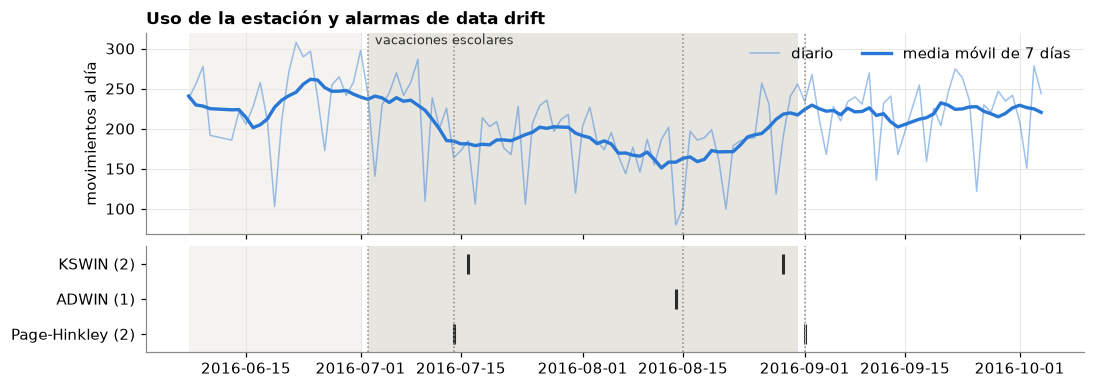

In [ ]:
# Uso real de la estación (movimientos al día), su media móvil de 7 días y alarmas de los tres detectores (calculadas sobre la anomalía)
dibujar_detecciones(diarias["movimientos_dia"], alarmas["uso_anomalia"],
                    "Uso de la estación y alarmas de data drift", "movimientos al día",
                    desde=INICIO_EVALUACION, suavizada=diarias["movimientos_dia"].rolling(7, center=True, min_periods=4).mean())

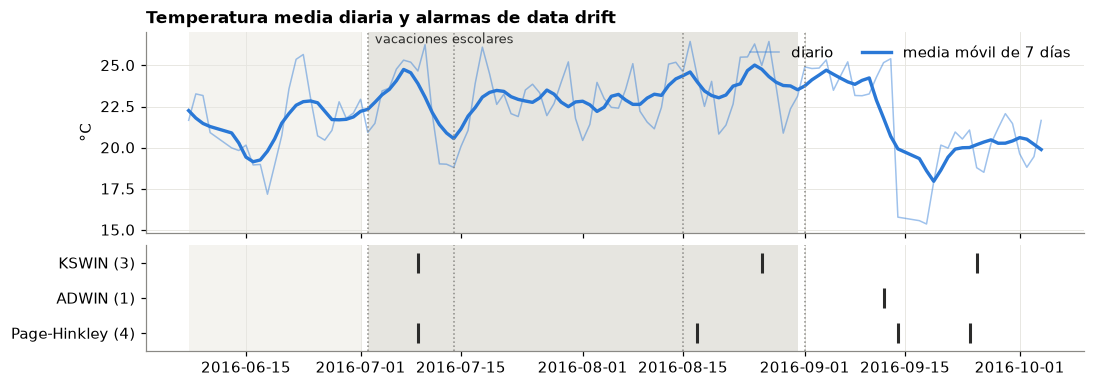

In [ ]:
# Temperatura media diaria, su media móvil de 7 días y alarmas de los tres detectores
dibujar_detecciones(diarias["temperatura"], alarmas["temperatura"],
                    "Temperatura media diaria y alarmas de data drift", "°C",
                    desde=INICIO_EVALUACION, suavizada=diarias["temperatura"].rolling(7, center=True, min_periods=4).mean())

- **El uso cambia con las vacaciones:** KSWIN y Page-Hinkley coinciden a **mediados de julio** (14-16), cuando el uso empieza a caer, y a **finales de agosto** (29 de agosto y 1 de septiembre), cuando se recupera con la vuelta a clase. La estación pasa de unos 240 movimientos al día en la segunda quincena de junio a unos 180 en agosto (un 25 % menos) y vuelve a unos 225 en septiembre. ADWIN solo salta una vez, el 14 de agosto, en el punto más bajo.
- **La temperatura baja de golpe el 14 de septiembre**, de 25 °C a 16 °C de media, y ya no vuelve a los valores de verano: Page-Hinkley lo detecta ese mismo día y KSWIN el 25. El resto de alarmas de temperatura (principios de julio, mediados y finales de agosto) son olas de calor y días frescos pasajeros.
- **Ninguno de los dos cambios altera el modelo:** el uso cambia **cuánto** se usa la estación, no **cómo** se vacía, y el aprendizaje online lo absorbe (apartado 4.5.4); y el ARF sin variables meteorológicas falla incluso algo menos (apartado 4.5.2). Un detector de *data drift* sirve para avisar de un cambio de comportamiento sin esperar a las etiquetas, no para reentrenar.

### 4.6.3 Tipos de día con clustering online

En el apartado 4.6.1 ya pasamos a un flujo diario para vigilar el uso. Con ese mismo flujo diario se puede preguntar otra cosa: no **cuándo** cambia el uso, sino **qué tipos de día** hay y de cuál es cada día nuevo.

**Objetivo.** Detectar sin etiquetas los días en que *pomme* no se llena, para **avisar al operador** y saber **cuándo la alerta es menos fiable**.

**Datos.** Un flujo de días construido online a partir del de 30 minutos, con solo **2 variables**:
- `bicis_10_16`: bicis medias de 10:00 a 16:00 (¿se ha llenado la estación?)
- `bicis_18_24`: bicis medias de 18:00 a 24:00 (¿se ha vaciado por la tarde?)

Las dos están en bicis, así que no hace falta estandarizar. Como en el resto del cuaderno, **junio es calibración** y se evalúa desde el despliegue (1 de julio).

**Modelo.** `cluster.KMeans` (K-Means incremental) y no DBSTREAM, porque el número de grupos se conoce y solo hay una instancia por día:
- `n_clusters=2`: el exploratorio (4.2) muestra dos comportamientos
- `halflife=0.1`: cada día mueve su centroide un 10 % (memoria de unas dos semanas)
- `mu=6`: las bicis medias, para que los centroides iniciales nazcan dentro de los datos

In [ ]:
# Clustering online de los días: K-Means incremental con 2 variables por día
def flujo_dias(instancias):
    """Agrega el flujo de 30 min en un flujo de días: emite cada día completo en cuanto termina."""
    dias, actual = collections.defaultdict(lambda: {"bicis_10_16": [], "bicis_18_24": []}), None
    for x, _ in instancias:
        t = pd.Timestamp(x["momento"]) - pd.Timedelta("30min")       # la instancia de las 0:00 es del día anterior
        if actual is not None and t.normalize() != actual:
            d = dias.pop(actual)
            if len(d["bicis_10_16"]) == 12 and len(d["bicis_18_24"]) == 12:   # solo días sin huecos
                yield actual, {k: float(np.mean(v)) for k, v in d.items()}
        actual = t.normalize()
        if 10 <= t.hour < 16:
            dias[actual]["bicis_10_16"].append(x["bicis"])
        elif 18 <= t.hour < 24:
            dias[actual]["bicis_18_24"].append(x["bicis"])

# Mismas unidades (bicis) en las dos variables: no hace falta estandarizar
km = cluster.KMeans(n_clusters=2, halflife=0.1, mu=6, sigma=1, seed=1)
for centro in km.centers.values():                    # crea los centroides iniciales en orden fijo (reproducible)
    centro["bicis_10_16"], centro["bicis_18_24"]
centros_mes = {}                                      # centroides al final de cada mes (para la gráfica)
filas = []
for dia, x in flujo_dias(flujo_bicis()):
    km.learn_one(x)                                   # aprende del día (sin etiqueta)
    filas.append({"dia": dia, "cluster": km.predict_one(x), **x})
    centros_mes[dia.month] = {c: dict(centro) for c, centro in km.centers.items()}
tipos = pd.DataFrame(filas).set_index("dia")
tipos = tipos[tipos.index >= INICIO_EVALUACION]       # junio es calibración: se evalúa desde el despliegue (1 de julio)

flojo = min(km.centers, key=lambda c: km.centers[c]["bicis_10_16"])
tipos["tipo"] = np.where(tipos["cluster"] == flojo, "flojo", "llenado")
print("Centroides:", {("flojo" if c == flojo else "llenado"): {k: round(v, 1) for k, v in centro.items()}
                      for c, centro in km.centers.items()})
tabla = pd.crosstab(tipos["tipo"], tipos.index.dayofweek)
tabla.columns = ["lun", "mar", "mié", "jue", "vie", "sáb", "dom"]
print(tabla, "\n")
print("Laborables flojos (aviso al operador):",
      [f"{d:%a %d-%m}" for d in tipos[(tipos["tipo"] == "flojo") & (tipos.index.dayofweek < 5) & ~tipos.index.isin(FESTIVOS)].index])

# ¿Es fiable la alerta esos días? Accuracy del ARF del apartado 4.5 (reg_arf) por tipo de día, desde el despliegue
r = reg_arf[reg_arf.index >= INICIO_EVALUACION]
dia = (r.index - pd.Timedelta("30min")).normalize()
acc = 100 * (1 - r["error"].groupby(dia.map(tipos["tipo"])).mean())
print("\nAccuracy del ARF por tipo de día (%):", acc.round(1).to_dict())

Centroides: {'llenado': {'bicis_10_16': 14.1, 'bicis_18_24': 4.5}, 'flojo': {'bicis_10_16': 5.0, 'bicis_18_24': 5.8}}
         lun  mar  mié  jue  vie  sáb  dom
tipo                                      
flojo      3    3    2    1    1    1   12
llenado   11   10   10   11   11   13    1 

Laborables flojos (aviso al operador): ['Tue 05-07', 'Tue 12-07', 'Fri 22-07', 'Mon 12-09', 'Wed 14-09', 'Mon 19-09', 'Tue 20-09', 'Wed 21-09']

Accuracy del ARF por tipo de día (%): {'flojo': 76.8, 'llenado': 85.5}


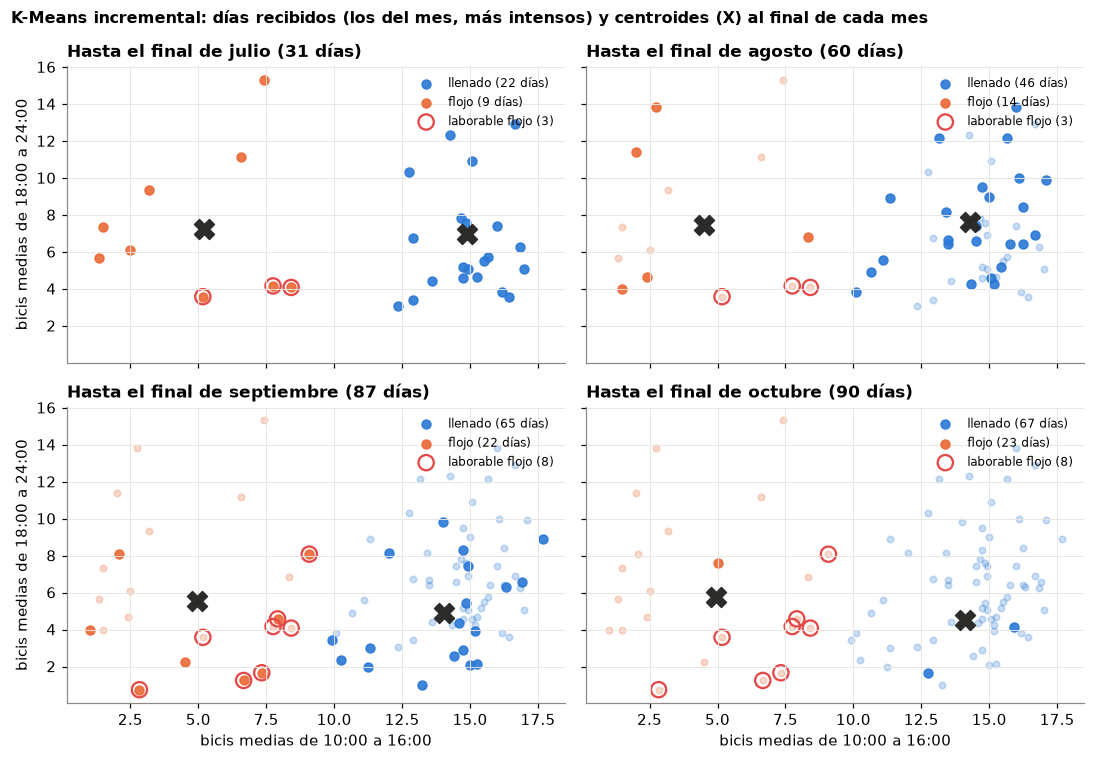

In [ ]:
# Gráfica 2x2: días que va recibiendo el K-Means (acumulados mes a mes) y centroides (X) al final de cada mes
MESES = {7: "julio", 8: "agosto", 9: "septiembre", 10: "octubre"}
COLOR = {"llenado": AZUL, "flojo": NARANJA}
laborable_flojo = (tipos["tipo"] == "flojo") & (tipos.index.dayofweek < 5) & ~tipos.index.isin(FESTIVOS)

fig, axes = plt.subplots(2, 2, figsize=(10, 7), sharex=True, sharey=True)
for ax, (mes, nombre_mes) in zip(axes.flat, MESES.items()):
    hasta = tipos[tipos.index.month <= mes]                     # todos los días recibidos hasta el final del mes
    for tipo, color in COLOR.items():
        anteriores = hasta[(hasta["tipo"] == tipo) & (hasta.index.month < mes)]
        del_mes = hasta[(hasta["tipo"] == tipo) & (hasta.index.month == mes)]
        ax.scatter(anteriores["bicis_10_16"], anteriores["bicis_18_24"], color=color, s=18, alpha=0.25)
        ax.scatter(del_mes["bicis_10_16"], del_mes["bicis_18_24"], color=color, s=34, alpha=0.9,
                   label=f"{tipo} ({(hasta['tipo'] == tipo).sum()} días)")
    marcados = hasta[laborable_flojo.loc[hasta.index]]
    ax.scatter(marcados["bicis_10_16"], marcados["bicis_18_24"], facecolors="none", edgecolors=ROJO, s=100, lw=1.5,
               label=f"laborable flojo ({len(marcados)})")
    for centro in centros_mes[mes].values():
        ax.scatter(centro["bicis_10_16"], centro["bicis_18_24"], marker="X", s=170, color=TINTA, zorder=5)
    ax.set_title(f"Hasta el final de {nombre_mes} ({len(hasta)} días)")
    ax.legend(frameon=False, fontsize=8, loc="upper right")
for ax in axes[1]:
    ax.set_xlabel("bicis medias de 10:00 a 16:00")
for ax in axes[:, 0]:
    ax.set_ylabel("bicis medias de 18:00 a 24:00")
fig.suptitle("K-Means incremental: días recibidos (los del mes, más intensos) y centroides (X) al final de cada mes",
             fontsize=10.5, fontweight="bold", x=0.01, ha="left")
plt.tight_layout()
plt.show()

- Salen dos tipos de día: **"llenado"** (unas 14 bicis de 10 a 16 h) y **"flojo"** (unas 5).
- **Casi coinciden con el calendario, con un matiz:** el domingo es flojo (12 de 13), pero el sábado se comporta como un laborable (13 de 14 de llenado). Agrupar sábado y domingo como "fin de semana", como hacen el exploratorio y la desestacionalización del apartado 4.6.1, mezcla dos comportamientos distintos. Además, **8 laborables son flojos**: el 5, 12 y 22 de julio y el 12, 14, 19, 20 y 21 de septiembre.
- **En los días flojos el ARF del apartado 4.5 acierta el 76,8 %, frente al 85,5 %** en los de llenado.

**Finalidad.** Al cerrar cada día, el sistema marca los laborables flojos y avisa al operador para que revise la estación (5 de los 8 fueron en septiembre). Esos días la alerta es casi 9 puntos menos fiable.

## 4.7 *Concept drift* controlado y estrategias de adaptación

En el flujo real de *pomme* el *concept drift* es leve y el ARF online lo absorbe (apartado 4.5), así que con él no se puede medir el **retardo** y las **falsas alarmas** de cada detector ante un cambio de fecha conocida, ni comparar **estrategias de adaptación**. Para eso construimos un *concept drift* **fuerte y conocido con datos reales**: el sistema, que ha aprendido con *pomme*, empieza a recibir el **1 de agosto** los datos de *place-jeanne-darc*, como si se desplegara en otro punto de la ciudad. Desde ese momento cambia la relación entre las variables y la alerta, así que los detectores deberían saltar. Usamos *place-jeanne-darc* porque, en una comprobación previa con las otras estaciones (que no incluimos para no alargar el cuaderno), fue la única con la que el modelo que viene de *pomme* empeora claramente.

### 4.7.1 Construcción del escenario

Repetimos la construcción del apartado 4.1 para las dos estaciones y unimos los flujos: *pomme* hasta el 31 de julio y *place-jeanne-darc* desde el 1 de agosto. El flujo con el cambio se guarda como CSV y se lee con `river.stream.iter_csv`, igual que el de *pomme*.

In [ ]:
# Flujo con el cambio: pomme hasta el 31 de julio y place-jeanne-darc desde el 1 de agosto (misma construcción que en el apartado 4.1)
crudo = pd.read_csv(dataset.path, parse_dates=["moment"]).drop_duplicates()


def construir_flujo(estacion, inicio="2016-06-01"):
    """Flujo regular de 30 minutos de una estación, con las mismas variables y etiqueta que en el apartado 4.1."""
    serie = crudo[(crudo["station"] == estacion) & (crudo["moment"] >= inicio)].set_index("moment").sort_index()
    reg = serie.resample(FREQ, label="right", closed="right").last()
    hay_dato = serie["bikes"].resample(FREQ, label="right", closed="right").count() > 0
    f = pd.DataFrame(index=reg.index)
    f["bicis"] = reg["bikes"].where(hay_dato)
    f["tendencia_1h"] = f["bicis"] - f["bicis"].shift(2)
    f["hora"] = f.index.hour + f.index.minute / 60
    f["dia_semana"] = f.index.dayofweek
    f["es_finde"] = (f.index.dayofweek >= 5).astype(int)
    f["es_festivo"] = f.index.normalize().isin(FESTIVOS).astype(int)
    for original, nuevo in METEO.items():
        f[nuevo] = reg[original].where(hay_dato)
    f["llueve"] = reg["description"].str.contains("rain|drizzle|thunderstorm", na=False).astype(int).where(hay_dato)
    f["movimientos_30min"] = serie["bikes"].diff().abs().resample(FREQ, label="right", closed="right").sum().where(hay_dato)
    f["bicis_2h"] = f["bicis"].reindex(f.index + pd.Timedelta(HORIZONTE)).to_numpy()
    f["pocas_bicis_2h"] = (f["bicis_2h"] <= UMBRAL_POCAS).astype(int).where(f["bicis_2h"].notna())
    f = f.dropna(subset=["bicis", "pocas_bicis_2h"])
    f.index.name = "momento"
    return f


CAMBIO = pd.Timestamp("2016-08-01")
ESTACION_NUEVA = "place-jeanne-darc"
antes, despues = construir_flujo("pomme"), construir_flujo(ESTACION_NUEVA)
cambio = pd.concat([antes[antes.index < CAMBIO], despues[despues.index >= CAMBIO]])
CSV_CAMBIO = "flujo_cambio_estacion.csv"
cambio.to_csv(CSV_CAMBIO, date_format="%Y-%m-%d %H:%M:%S")


def flujo_cambio(ruta=CSV_CAMBIO):
    for x, y in stream.iter_csv(ruta, target="pocas_bicis_2h", converters=CONVERTIDORES,
                                parse_dates={"momento": "%Y-%m-%d %H:%M:%S"}, drop=["bicis_2h"]):
        yield {k: v for k, v in x.items() if v is not None}, y


print(f"{len(cambio):,} instancias: {(cambio.index < CAMBIO).sum():,} de pomme (1 jun-31 jul) y "
      f"{(cambio.index >= CAMBIO).sum():,} de {ESTACION_NUEVA} (1 ago-5 oct)")

5,795 instancias: 2,927 de pomme (1 jun-31 jul) y 2,868 de place-jeanne-darc (1 ago-5 oct)


In [ ]:
# Bucle prequential que puede sustituir el modelo por uno nuevo cuando salta un detector o en una fecha fija
def prequential_cambio(fabrica_modelo, instancias, retraso=HORIZONTE, detector=None, reiniciar=False, reinicio_en=None):
    """Igual que `prequential` (apartado 4.3.1): en cada instancia llegan primero las etiquetas de hace 2 horas (se evalúa,
    se actualiza el detector y el modelo aprende) y después se predice la nueva. Recibe una fábrica de modelos para poder reiniciarlo:
    detector: recibe el bit de error; si reiniciar=True, cada drift (desde INICIO_EVALUACION) sustituye el modelo por uno nuevo.
    reinicio_en: fecha en que el modelo se sustituye por uno nuevo (el 'oráculo' que sabe cuándo ocurre el cambio).
    Devuelve (registro por instancia, fechas de drift)."""
    retraso = pd.Timedelta(retraso)
    modelo = fabrica_modelo()
    pendientes, registros, drifts = collections.deque(), [], []
    reiniciado = False
    for x, y in instancias:
        t = x["momento"]
        if reinicio_en is not None and not reiniciado and t >= reinicio_en:
            modelo, reiniciado = fabrica_modelo(), True
        while pendientes and pendientes[0][0] + retraso <= t:
            t0, x0, y0, p0 = pendientes.popleft()
            error = int(p0 != y0)
            registros.append((t0, t, error))
            if detector is not None:
                detector.update(error)
                if t >= INICIO_EVALUACION and detector.drift_detected:
                    drifts.append(t)
                    if reiniciar:
                        modelo = fabrica_modelo()
            modelo.learn_one(x0, y0)
        xm = variables_modelo(x)
        p = modelo.predict_one(xm)
        pendientes.append((t, xm, y, bool(p) if p is not None else False))
    registro = pd.DataFrame(registros, columns=["momento", "revelada", "error"]).set_index("momento")
    return registro, drifts

### 4.7.2 Detectores ante un cambio conocido

Ahora sí sabemos dónde está el drift: el **1 de agosto a las 0:00**. Aplicamos los tres detectores del apartado 4.5.3, con la misma configuración, a los errores del Hoeffding Tree y del ARF, y medimos si detectan el cambio en las 2 semanas siguientes, con qué **retardo** y cuántas **falsas alarmas** dan antes y después.

In [ ]:
# Detectores frente al cambio conocido, sobre los errores del Hoeffding Tree y del ARF: detección, retardo y falsas alarmas
FABRICAS_DET = {"HDDM_W": lambda: drift.binary.HDDMW(lambda_val=0.02),     # misma configuración que en el apartado 4.5.3
                "Page-Hinkley": lambda: drift.PageHinkley(mode="up", threshold=15),
                "ADWIN": lambda: drift.ADWIN(delta=0.05, clock=48)}
MODELOS_CAMBIO = {"Hoeffding Tree": tree.HoeffdingTreeClassifier,
                  "ARF": lambda: forest.ARFClassifier(n_models=ARBOLES, seed=SEMILLA)}
flujos_error = {nombre: prequential_cambio(fab, flujo_cambio())[0] for nombre, fab in MODELOS_CAMBIO.items()}

VENTANA = (CAMBIO, CAMBIO + pd.Timedelta("14D"))
filas, detecciones = [], {}
for nombre_modelo, reg in flujos_error.items():
    for nombre_det, fab in FABRICAS_DET.items():
        _, drifts = vigilar(fab(), list(zip(reg["revelada"], reg["error"])))
        detecciones[(nombre_modelo, nombre_det)] = drifts
        dentro = [d for d in drifts if VENTANA[0] <= d < VENTANA[1]]
        filas.append({"modelo": nombre_modelo, "detector": nombre_det,
                      "detecta el cambio (2 semanas)": "sí" if dentro else "no",
                      "retardo (días)": (dentro[0] - CAMBIO).total_seconds() / 86400 if dentro else np.nan,
                      "falsas alarmas antes del cambio (julio)": sum(d < CAMBIO for d in drifts),
                      "alarmas después de las 2 semanas": sum(d >= VENTANA[1] for d in drifts)})
pd.DataFrame(filas).set_index(["modelo", "detector"]).round(1)

detecta el cambio (2 semanas)  retardo (días)  falsas alarmas antes del cambio (julio)  alarmas después de las 2 semanas
modelo         detector                                                                                                                             
Hoeffding Tree HDDM_W                                  sí             4.1                                        3                                 5
               Page-Hinkley                            sí             4.1                                        3                                 8
               ADWIN                                   sí             2.2                                        3                                 5
ARF            HDDM_W                                  sí             4.2                                        1                                 5
               Page-Hinkley                            sí             4.2                                        1                                 4
               ADWIN                                   sí             4.4                                        0                                 5

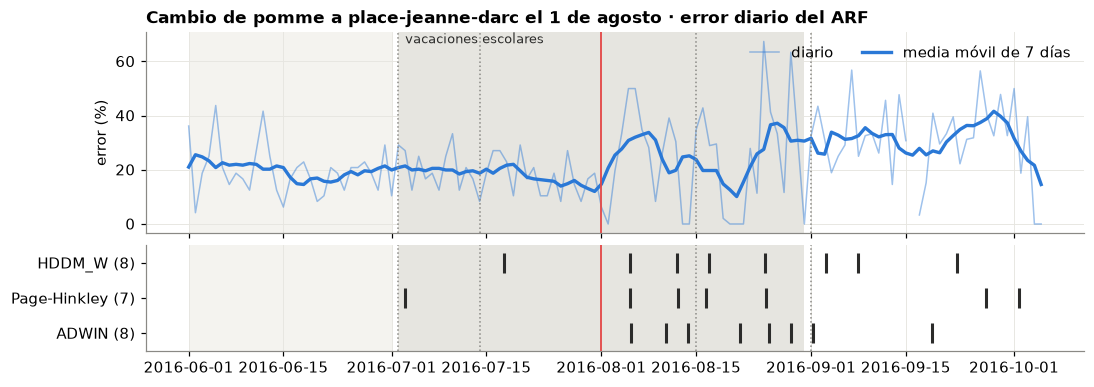

In [ ]:
# Error diario del ARF, su media móvil de 7 días y detecciones de los tres detectores (línea roja: cambio de estación)
diario = 100 * flujos_error["ARF"]["error"].resample("D").mean()
dibujar_detecciones(diario, {d: detecciones[("ARF", d)] for d in FABRICAS_DET},
                    f"Cambio de pomme a {ESTACION_NUEVA} el 1 de agosto · error diario del ARF", "error (%)",
                    desde=INICIO_EVALUACION, suavizada=diario.rolling(7, center=True, min_periods=4).mean(), cambio=CAMBIO)

- **Los tres detectores detectan el cambio** en los dos modelos, entre 2 y 4,5 días después del 1 de agosto. Ninguno reacciona en horas: con una etiqueta que llega 2 horas tarde, necesitan días de evidencia.
- **Sobre el ARF dan menos falsas alarmas que sobre el Hoeffding Tree** (0 o 1 en julio, frente a 3): el error del ARF, que promedia 25 árboles, es más estable, y sus oscilaciones se confunden menos con un cambio. Después del cambio todos siguen saltando, porque septiembre es más difícil en *place-jeanne-darc*.

### 4.7.3 Estrategias de adaptación

Detectar solo sirve si después se hace algo. Comparamos, ante el mismo cambio de estación, las estrategias de adaptación del tema:

| Estrategia | Qué hace | Estrategia del tema |
|---|---|---|
| Sin reacción | Hoeffding Tree que sigue aprendiendo online, sin detector | actualización incremental |
| Oráculo | se sustituye el modelo por uno nuevo **justo el 1 de agosto** (nadie sabe eso en la realidad: es la referencia de lo mejor que puede hacer un reinicio) | reentrenamiento completo |
| Reinicio con X | cuando el detector X (HDDM_W, Page-Hinkley o ADWIN) salta, se sustituye el modelo por uno nuevo | detección + reentrenamiento completo |
| Hoeffding Adaptive Tree | árbol con ADWIN en cada nodo: sustituye solo las ramas afectadas | sustitución parcial del modelo |
| ARF | bosque con un detector ADWIN por árbol: sustituye los árboles que empeoran | ensamblado dinámico |

                           error total (%)  reinicios antes  reinicios después
Sin reacción                          28.4              0.0                0.0
Oráculo                               27.6              0.0                0.0
Reinicio con HDDM_W                   29.6              2.0                8.0
Reinicio con Page-Hinkley             28.8              2.0                8.0
Reinicio con ADWIN                    28.9              1.0                7.0
Hoeffding Adaptive Tree               26.1              0.0                0.0
ARF                                   24.9              0.0                0.0


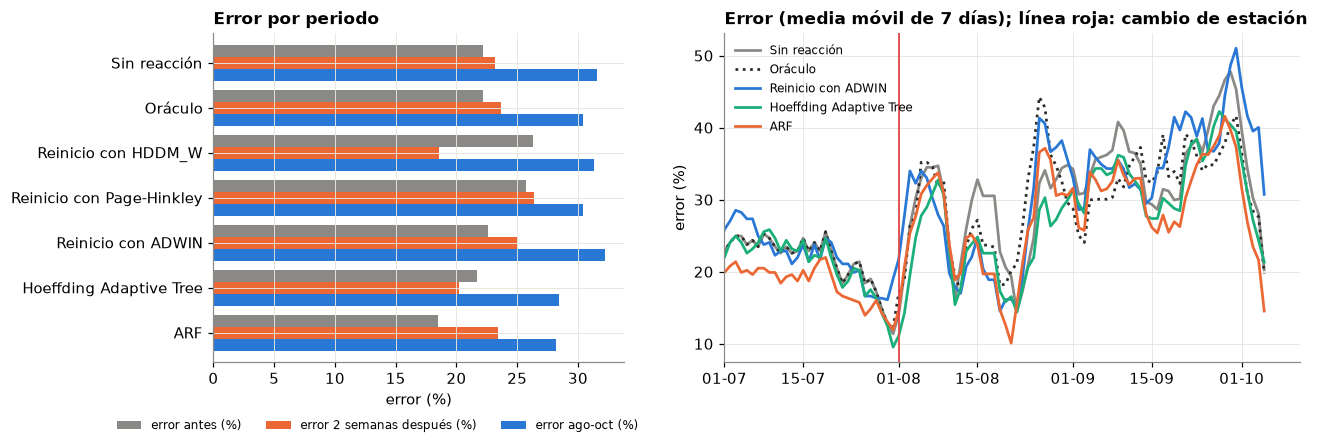

In [ ]:
# Estrategias de adaptación ante el cambio de estación: error por periodo y su evolución (media móvil de 7 días)
def medir_estrategia(registro, drifts=()):
    e = registro["error"]
    return {"error antes (%)": 100 * e[INICIO_EVALUACION:CAMBIO].mean(),
            "error 2 semanas después (%)": 100 * e[CAMBIO:CAMBIO + pd.Timedelta("14D")].mean(),
            "error ago-oct (%)": 100 * e[CAMBIO:].mean(),
            "error total (%)": 100 * e[INICIO_EVALUACION:].mean(),
            "reinicios antes": sum(d < CAMBIO for d in drifts),
            "reinicios después": sum(d >= CAMBIO for d in drifts)}


HT = tree.HoeffdingTreeClassifier
registros_estr, estrategias = {}, {}
registros_estr["Sin reacción"], _ = prequential_cambio(HT, flujo_cambio())
registros_estr["Oráculo"], _ = prequential_cambio(HT, flujo_cambio(), reinicio_en=CAMBIO)
estrategias = {n: medir_estrategia(r) for n, r in registros_estr.items()}
for nombre_det, fab in FABRICAS_DET.items():
    nombre = f"Reinicio con {nombre_det}"
    registros_estr[nombre], drifts = prequential_cambio(HT, flujo_cambio(), detector=fab(), reiniciar=True)
    estrategias[nombre] = medir_estrategia(registros_estr[nombre], drifts)
registros_estr["Hoeffding Adaptive Tree"], _ = prequential_cambio(lambda: tree.HoeffdingAdaptiveTreeClassifier(seed=SEMILLA), flujo_cambio())
registros_estr["ARF"] = flujos_error["ARF"]
for nombre in ["Hoeffding Adaptive Tree", "ARF"]:
    estrategias[nombre] = medir_estrategia(registros_estr[nombre])
tabla_estrategias = pd.DataFrame(estrategias).T.round(1)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1, 1.4]})
tabla_estrategias[["error antes (%)", "error 2 semanas después (%)", "error ago-oct (%)"]].plot.barh(
    ax=a1, color=[GRIS, NARANJA, AZUL], width=0.8)
a1.invert_yaxis(); a1.set_xlabel("error (%)"); a1.set_title("Error por periodo")
a1.legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.4, -0.14), ncol=3)
for nombre, color, ls in [("Sin reacción", GRIS, "-"), ("Oráculo", TINTA, ":"), ("Reinicio con ADWIN", AZUL, "-"),
                          ("Hoeffding Adaptive Tree", VERDE, "-"), ("ARF", NARANJA, "-")]:
    s = 100 * registros_estr[nombre]["error"].resample("D").mean().rolling(7, center=True, min_periods=4).mean()
    a2.plot(s.index, s.values, color=color, ls=ls, lw=1.8, label=nombre)
a2.axvline(CAMBIO, color=ROJO, lw=1.2); a2.set_xlim(left=INICIO_EVALUACION)
a2.set_title("Error (media móvil de 7 días); línea roja: cambio de estación"); a2.set_ylabel("error (%)")
a2.xaxis.set_major_formatter(mdates.DateFormatter("%d-%m"))
a2.legend(frameon=False, fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()
print(tabla_estrategias[["error total (%)", "reinicios antes", "reinicios después"]].to_string())

- **El ARF es la mejor estrategia** (24,9 % de error total): es el mejor antes del cambio (18,5 %) y de agosto a octubre (28,2 %), aunque tarda algo en reaccionar (23,4 % en las 2 semanas siguientes), porque sustituye poco a poco los árboles que empeoran sin tirar lo que sigue sirviendo. Confirma la elección del apartado 4.4: ante un cambio fuerte, el ensemble que se adapta solo supera al árbol único. El Hoeffding Adaptive Tree queda segundo (26,1 %) y es el que mejor reacciona sin detector externo (20,2 % en las 2 semanas siguientes).
- **Reiniciar con cualquiera de los tres detectores es peor que no hacer nada** (28,8-29,6 % de error total frente a 28,4 %): sus falsas alarmas reinician el modelo 1 o 2 veces antes del cambio y, después, el modelo recién reiniciado falla mucho, el detector vuelve a saltar y se encadenan 7 u 8 reinicios. Reiniciar con HDDM_W reacciona muy rápido (18,6 % en las 2 semanas siguientes), pero lo paga antes del cambio (26,3 %).
- **Incluso el oráculo**, que reinicia justo el 1 de agosto, solo mejora 0,8 puntos a no reaccionar (27,6 %): reiniciar tira también lo que sigue sirviendo, porque el ciclo diario se parece en las dos estaciones. Para adaptarse importa más no reaccionar a falsas alarmas que detectar rápido.

## 4.8 Flujo de avisos de usuarios: clasificación de texto online

**Objetivo.** Clasificar cada aviso de los usuarios **en cuanto llega** para enviarlo al equipo que debe atenderlo, aprendiendo de la categoría que pone el operador cuando lo atiende (1 hora después):

| Categoría | Ejemplo | Equipo |
|---|---|---|
| `sin_bicis` | *"plus aucun vélo à Pomme"* | redistribución |
| `estacion_llena` | *"impossible de rendre mon vélo, tout est plein"* | redistribución |
| `averia` | *"pneu crevé, vélo 214 inutilisable"* | taller |
| `averia_estacion` | *"la borne ne lit pas ma carte"* (solo desde el 1 de septiembre) | mantenimiento de estaciones |
| `app_pago` | *"paiement refusé alors que ma carte marche"* | soporte técnico |
| `otro` | *"quels sont les tarifs pour un abonnement annuel ?"* | atención al cliente |

**Dos sistemas para el mismo problema.** Las quejas `sin_bicis` van al equipo de redistribución, el mismo que recibe la alerta del apartado 4.4. Ese equipo puede enterarse de que *pomme* se queda sin bicis por dos vías:
- el **sistema anticipativo**: la alerta del ARF, que lo predice 2 horas antes;
- el **sistema reactivo**: un usuario se queja, este clasificador envía el aviso como `sin_bicis` y llega a redistribución cuando el problema ya ha llegado al usuario.

La gracia de tener los dos es comprobar si el anticipativo avisa antes (apartado 4.9).

### 4.8.1 El flujo de avisos

No hay datos públicos de avisos de usuarios de un sistema de bicis, así que los **generamos a partir del estado real de *pomme***: en cada media hora, el número de avisos de cada tipo sigue una Poisson que depende de las bicis reales (las quejas `sin_bicis` aparecen cuando la estación está vacía) y de la actividad real a esa hora. El texto está en **francés** (y en inglés en verano), con un 20 % de erratas, un 25 % sin tildes y un 3 % de etiquetas mal puestas. Incluye **cambios con fecha conocida** para medir cómo responden los modelos:

| Fecha | Cambio | Tipo |
|---|---|---|
| 6 jul - 31 ago | Turistas: el 35 % de los avisos, en inglés | *data drift* |
| 1 sep | El operador **reorganiza sus categorías**: los avisos de la borne pasan de `averia` a `averia_estacion` | ***concept drift*** |
| 12-14 sep | Avería de la borne: avisos de `averia_estacion` ×8 | clase nueva masiva |

El flujo se lee con `river.stream.iter_csv`, aviso a aviso. Las columnas `idioma` y `causa` son la verdad del generador: el modelo nunca las ve.

In [ ]:
# --- Plantillas de los avisos: francés (usuarios locales) e inglés (turistas) ---------------------------
ESTACION_FR = ["à Pomme", "station Pomme", "à la station Pomme", "rue de la Pomme", ""]
ESTACION_EN = ["at Pomme", "at the Pomme station", ""]
PLANTILLAS_FR = {
    "sin_bicis": ["plus aucun vélo {est}", "station vide {est}", "il n'y a plus de vélos {est}",
                  "aucun vélo, toutes les bornes sont libres {est}", "je voulais prendre un vélo {est} mais il n'y en avait aucun"],
    "estacion_llena": ["station pleine {est}", "impossible de rendre mon vélo {est}, tout est plein", "aucune place libre {est}",
                       "toutes les bornes sont occupées {est}", "où je pose le vélo ? {est} c'est plein"],
    "averia": ["le frein du vélo ne marche pas", "pneu crevé, vélo {num} inutilisable", "chaîne cassée sur le vélo {num}",
               "la selle du vélo {num} est cassée", "le vélo {num} est cassé, je l'ai laissé {est}"],
    "averia_estacion": ["la borne {est} ne fonctionne pas", "l'écran de la borne {est} est noir", "la borne {est} ne lit pas ma carte",
                        "le vélo ne se décroche pas de la borne {est}", "terminal hors service {est}"],
    "app_pago": ["l'application plante quand je veux payer", "paiement refusé alors que ma carte marche", "on m'a débité deux fois",
                 "impossible de me connecter à l'application", "l'appli ne m'envoie pas le code"],
    "otro": ["quels sont les tarifs pour un abonnement annuel ?", "merci pour le service, très pratique",
             "est-ce que la station Pomme est ouverte la nuit ?", "il faudrait plus de stations dans le quartier",
             "proposition : mettre des vélos électriques"],
}
PLANTILLAS_EN = {
    "sin_bicis": ["no bikes available {est}", "the station is empty {est}", "not a single bike {est}"],
    "estacion_llena": ["station full {est}, can't return my bike", "no free dock {est}", "all docks are occupied {est}"],
    "averia": ["bike {num} has a flat tire", "the brakes don't work on bike {num}", "broken chain on bike {num}"],
    "averia_estacion": ["the terminal {est} is not working", "the kiosk screen {est} is black", "card reader broken {est}"],
    "app_pago": ["the app crashes when I try to pay", "my card was declined in the app", "I was charged twice"],
    "otro": ["how much is a day pass?", "great service, thanks!", "is there a weekly pass for tourists?"],
}
INICIO_FR = ["", "", "", "bonjour, ", "salut, ", "allô ? ", "encore une fois : "]
FIN_FR = ["", "", "", " merci", " !!", " svp", ", c'est pénible", ", c'est la troisième fois cette semaine"]
INICIO_EN = ["", "", "hi, ", "hello, "]
FIN_EN = ["", "", " thanks", ", please help"]

In [ ]:
# Generador del flujo de avisos a partir del estado real de pomme
SEMILLA_AVISOS = 2016
VERANO = (pd.Timestamp("2016-07-06"), pd.Timestamp("2016-09-01"))     # turistas: más avisos en inglés
REORGANIZACION = pd.Timestamp("2016-09-01")                             # el operador crea la categoría averia_estacion
AVERIA_BORNE = (pd.Timestamp("2016-09-12"), pd.Timestamp("2016-09-15"))  # la borne de pomme se estropea
RETRASO_AVISOS = pd.Timedelta("1h")                                     # el operador etiqueta el aviso 1 hora después


def con_erratas(texto, rng, p=0.2):
    """Con probabilidad p, borra, duplica o intercambia una letra de una palabra (errata de teclado)."""
    if rng.random() >= p:
        return texto
    palabras = texto.split(" ")
    largas = [i for i, w in enumerate(palabras) if len(w) > 4]
    if not largas:
        return texto
    i = rng.choice(largas)
    w, j = palabras[i], rng.integers(1, len(palabras[i]) - 1)
    op = rng.integers(3)
    palabras[i] = w[:j] + w[j + 1:] if op == 0 else w[:j] + w[j] + w[j:] if op == 1 else w[:j - 1] + w[j] + w[j - 1] + w[j + 1:]
    return " ".join(palabras)


def redactar(causa, ingles, rng):
    """Escribe un aviso de la causa indicada combinando plantilla, estación, saludo y coletilla, con ruido."""
    plantillas, est, ini, fin = ((PLANTILLAS_EN, ESTACION_EN, INICIO_EN, FIN_EN) if ingles
                                 else (PLANTILLAS_FR, ESTACION_FR, INICIO_FR, FIN_FR))
    t = rng.choice(plantillas[causa]).format(est=rng.choice(est), num=rng.integers(100, 999))
    t = (rng.choice(ini) + t + rng.choice(fin)).replace("  ", " ").strip()
    if rng.random() < 0.3:
        t = t.lower()
    if not ingles and rng.random() < 0.25:               # muchos usuarios escriben sin tildes
        for con, sin in [("é", "e"), ("è", "e"), ("ê", "e"), ("à", "a"), ("ç", "c"), ("ô", "o"), ("î", "i"), ("û", "u")]:
            t = t.replace(con, sin)
    return con_erratas(t, rng)


def generar_avisos(flujo, semilla=SEMILLA_AVISOS):
    """Genera los avisos de los usuarios a partir del estado REAL de pomme en cada media hora."""
    rng = np.random.default_rng(semilla)
    actividad = flujo.groupby(["hora", "es_finde"])["movimientos_30min"].mean()   # uso real por franja
    actividad = actividad / actividad.max()
    filas = []
    for t, f in flujo.iterrows():
        a = actividad.get((f["hora"], f["es_finde"]), 0.0)
        verano = VERANO[0] <= t < VERANO[1]
        intensidad = {                                   # avisos esperados en esta media hora (x2: volumen total)
            "sin_bicis": 2 * a * (1.0 if f["bicis"] == 0 else 0.35 if f["bicis"] <= 2 else 0.01),
            "estacion_llena": 2 * a * (0.7 if f["bicis"] >= 17 else 0.1 if f["bicis"] >= 15 else 0.0),
            "averia": 2 * 0.10 * a,
            "averia_estacion": 2 * 0.06 * a * (8 if AVERIA_BORNE[0] <= t < AVERIA_BORNE[1] else 1),
            "app_pago": 2 * 0.06 * a,
            "otro": 2 * 0.05 * a * (2 if verano else 1),
        }
        for causa, lam in intensidad.items():
            for _ in range(rng.poisson(lam)):
                ingles = rng.random() < (0.35 if verano else 0.05)
                momento = t - pd.Timedelta(minutes=30) + pd.Timedelta(seconds=int(rng.integers(0, 1800)))
                # Categoría que pone el operador: antes de la reorganización, las averías de la estación son "averia"
                categoria = "averia" if causa == "averia_estacion" and momento < REORGANIZACION else causa
                filas.append((momento, redactar(causa, ingles, rng), "en" if ingles else "fr", causa, categoria))
    avisos = pd.DataFrame(filas, columns=["momento", "texto", "idioma", "causa", "categoria"])
    avisos = avisos.sort_values("momento", kind="stable").reset_index(drop=True)
    # El operador se equivoca en el 3 % de las etiquetas
    ruido = rng.random(len(avisos)) < 0.03
    antes = ["sin_bicis", "estacion_llena", "averia", "app_pago", "otro"]
    avisos.loc[ruido, "categoria"] = [rng.choice(antes + (["averia_estacion"] if m >= REORGANIZACION else []))
                                      for m in avisos.loc[ruido, "momento"]]
    return avisos


avisos = generar_avisos(flujo)
CSV_AVISOS = "avisos_pomme.csv"
avisos.to_csv(CSV_AVISOS, index=False, date_format="%Y-%m-%d %H:%M:%S")
print(f"Guardado {CSV_AVISOS}: {len(avisos):,} avisos del {avisos['momento'].min():%d-%m} al {avisos['momento'].max():%d-%m}")
avisos.sample(12, random_state=3)[["momento", "texto", "idioma", "categoria"]].sort_values("momento")

Guardado avisos_pomme.csv: 2,528 avisos del 01-06 al 05-10


,momento,texto,idioma,categoria
759,2016-07-07 18:58:39,"impossible de rendre mon vélo à pomm, tout est plein",fr,estacion_llena
894,2016-07-14 09:05:00,"hi, not a single bike at the Pomme station",en,sin_bicis
1051,2016-07-21 15:37:13,allo ? où je pose le velo ? a la station Pomme c'est plein,fr,estacion_llena
1122,2016-07-24 15:38:36,je voulais prendre un velo mais il n'y en avait aucun merci,fr,sin_bicis
1204,2016-07-28 15:08:06,"hi, no free dock , please help",en,estacion_llena
1441,2016-08-09 12:01:06,où je pose le vélo ? c'est plein,fr,estacion_llena
1696,2016-08-22 18:35:42,"salut, proposition : mettre des vélos électriques",fr,otro
1713,2016-08-24 00:07:28,station vide à oPmme merci,fr,sin_bicis
2194,2016-09-17 12:34:17,"la borne rue de la Pomme ne lit pas ma carte, c'est pénible",fr,averia_estacion
2195,2016-09-17 15:39:24,"salut, toutes les bornes sont occupées rue de la Pomme",fr,estacion_llena


In [ ]:
# Lector del flujo de avisos con river.stream.iter_csv
def flujo_avisos(ruta=CSV_AVISOS, delay=0.0):
    """Simula la llegada de los avisos uno a uno. Devuelve (x, y) con x = {"texto", "momento", "idioma", "causa"}."""
    for x, y in stream.iter_csv(ruta, target="categoria", parse_dates={"momento": "%Y-%m-%d %H:%M:%S"}):
        yield x, y
        time.sleep(delay)


for x, y in islice(flujo_avisos(), 3):
    print(f"{x['momento']:%d-%m %H:%M} | {x['texto']!r} -> {y}")

01-06 00:37 | 'plus aucun velo station pomme meci' -> sin_bicis
01-06 00:47 | 'allô ? station vide station Pomme' -> sin_bicis
01-06 02:05 | "la selle du velo 965 est cassee, c'est penible" -> averia


2,528 avisos, 20 al día de media
{'sin_bicis': 24.7, 'averia': 24.7, 'estacion_llena': 23.3, 'otro': 12.2, 'app_pago': 10.2, 'averia_estacion': 4.9}


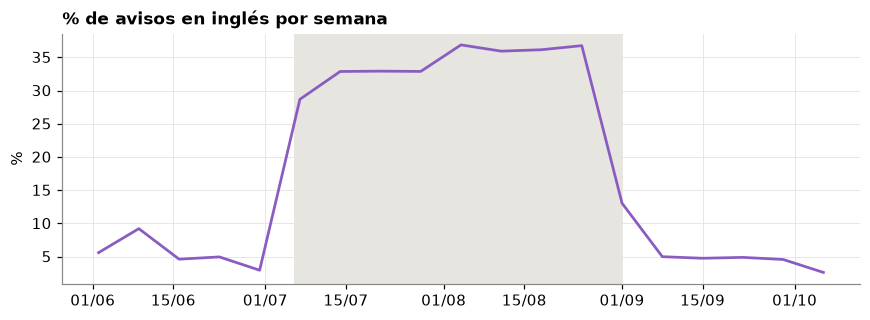

In [ ]:
# % de avisos en inglés por semana (zona gris: vacaciones de verano, cuando llegan los turistas)
ingles = avisos.set_index("momento")["idioma"].eq("en").resample("W-SUN").mean() * 100
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(ingles.index - pd.Timedelta(days=3), ingles.values, color=MORADO, lw=1.8)
ax.axvspan(*VERANO, color=SOMBRA, lw=0, zorder=0)
ax.set_title("% de avisos en inglés por semana"); ax.set_ylabel("%")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
plt.tight_layout(); plt.show()
print(f"{len(avisos):,} avisos, {avisos.groupby(avisos['momento'].dt.date).size().mean():.0f} al día de media")
print((100 * avisos["categoria"].value_counts(normalize=True)).round(1).to_dict())

Llegan unos **20 avisos al día** con clases desequilibradas: `sin_bicis`, `averia` y `estacion_llena` rondan el 24 % cada una, `otro` y `app_pago` el 10-12 % y `averia_estacion`, que solo existe desde septiembre, el 5 %. El inglés pasa del 5 % en junio a cerca del 35 % en agosto y vuelve al 5 % en septiembre.

### 4.8.2 Elección razonada del clasificador

**Evaluación:** *prequential* con la etiqueta **1 hora después**, con el mismo calendario que la alerta: los modelos se eligen con junio (del 15 al 30) y se evalúan desde el 1 de julio. Se mide la **F1 macro**, porque las clases están desequilibradas, y el **error en los avisos de la borne desde el 1 de septiembre**, que mide la adaptación al *concept drift*. *Baselines*: clase mayoritaria y **reglas de palabras clave** escritas con el vocabulario de junio.

| Qué exige el flujo | Naive Bayes multinomial + bolsa de palabras | Regresión logística One-vs-Rest + TF-IDF |
|---|---|---|
| Aprender aviso a aviso con pocos ejemplos | ✔ solo suma conteos | ✔ descenso por gradiente |
| **Olvidar**: las categorías las decide el operador y pueden cambiar | ✘ sus conteos acumulan todo el pasado | ✔ el gradiente da más peso a lo reciente (olvido implícito) |
| Admitir **clases nuevas** | ✔ | ✔ `OneVsRestClassifier` crea un clasificador por clase nueva |

Por eso esperamos que la regresión logística sea la mejor, sobre todo después del cambio de categorías. Va con **TF-IDF** porque, como todo modelo lineal entrenado por gradiente, necesita variables en una escala comparable; el Naive Bayes, con **bolsa de palabras**, porque trabaja con conteos. La tasa de aprendizaje de la regresión logística también se elige **solo con junio**.

In [ ]:
# Baselines (reglas de palabras clave y clase mayoritaria) y bucle prequential de los avisos
def normalizar(texto):
    """Minúsculas y sin tildes (igual que hacen por defecto BagOfWords y TFIDF de River)."""
    return "".join(c for c in unicodedata.normalize("NFKD", texto.lower()) if not unicodedata.combining(c))


class ReglasPalabrasClave:
    """Baseline sin aprendizaje: reglas escritas con el vocabulario de junio, en orden de prioridad."""
    REGLAS = [
        ("estacion_llena", r"plein|complete|place libre|sature|full|free dock|docks|deposer|rendre"),
        ("sin_bicis", r"aucun velo|plus de velo|pas de velo|zero velo|vide|no bikes|empty|any bike|single bike|introuvable|aucun"),
        ("averia", r"borne|terminal|ecran|lecteur|cadenas|kiosk|card reader|attache|decroche|frein|chaine|pneu|selle|guidon|roue"
                   r"|lumiere|brake|tire|chain|seat|damaged|casse|abime"),
        ("app_pago", r"appli|application|paiement|carte|debite|preleve|code|connecter|\bapp\b|charged|declined|log in"),
    ]

    def predict_one(self, x):
        t = normalizar(x["texto"])
        return next((clase for clase, patron in self.REGLAS if re.search(patron, t)), "otro")

    def learn_one(self, x, y):
        pass


def prequential_texto(modelo, avisos=None, retraso=RETRASO_AVISOS, detector=None, reiniciar=None, desde=pd.Timestamp("2016-06-15")):
    """Evaluación test-then-train de los avisos con la etiqueta retrasada `retraso`.
    detector: recibe el bit de error; si salta (desde la fecha `desde`) y `reiniciar` es una función, el modelo se sustituye.
    Devuelve (registro por aviso, fechas de drift)."""
    pendientes, registros, drifts = collections.deque(), [], []
    for x, y in (avisos if avisos is not None else flujo_avisos()):
        t = x["momento"]
        while pendientes and pendientes[0][0] + retraso <= t:          # 1) llegan las categorías de hace 1 hora
            t0, x0, y0, p0 = pendientes.popleft()
            error = int(p0 != y0)
            registros.append((t0, t, x0["idioma"], x0["causa"], y0, p0, error))
            if detector is not None:
                detector.update(error)
                if detector.drift_detected and t >= desde:
                    drifts.append(t)
                    if reiniciar is not None:
                        modelo = reiniciar()
            modelo.learn_one({"texto": x0["texto"]}, y0)
        xm = {"texto": x["texto"]}                                       # 2) llega un aviso: se clasifica
        pendientes.append((t, x, y, modelo.predict_one(xm)))
    registro = pd.DataFrame(registros, columns=["momento", "revelada", "idioma", "causa", "y", "y_pred", "error"])
    return registro.set_index("momento"), drifts


def resumen_texto(registro, desde=INICIO_EVALUACION, hasta=None):
    """Accuracy, F1 macro y error en los avisos de la borne desde el 1 de septiembre, de los avisos entre `desde` y `hasta`."""
    registro = registro[(registro.index >= desde) & ((registro.index < hasta) if hasta is not None else True)]
    acc, f1 = metrics.Accuracy(), metrics.MacroF1()
    for y, p in zip(registro["y"], registro["y_pred"]):
        acc.update(y, p if p is not None else "ninguna")
        f1.update(y, p if p is not None else "ninguna")
    despues = registro[registro.index >= REORGANIZACION]
    return {"accuracy (%)": round(100 * acc.get(), 1), "F1 macro (%)": round(100 * f1.get(), 1),
            "error en avisos de la borne desde el 1-sep (%)": round(100 * despues[despues["causa"] == "averia_estacion"]["error"].mean(), 1)}

Error en junio según la tasa de aprendizaje (%): {0.01: np.float64(59.6), 0.1: np.float64(31.9), 0.5: np.float64(14.6), 1.0: np.float64(11.0), 2.0: np.float64(8.8), 5.0: np.float64(8.0), 10.0: np.float64(8.6)}
Tasa elegida: 5.0
                          F1 macro 15-30 jun  accuracy desde julio  F1 macro desde julio
Clase mayoritaria                        8.6                  22.2                   9.4
Reglas de palabras clave                87.7                  81.3                  71.4
Naive Bayes multinomial                 94.0                  92.0                  86.5
Regresión logística OvR                 96.8                  95.9                  95.6


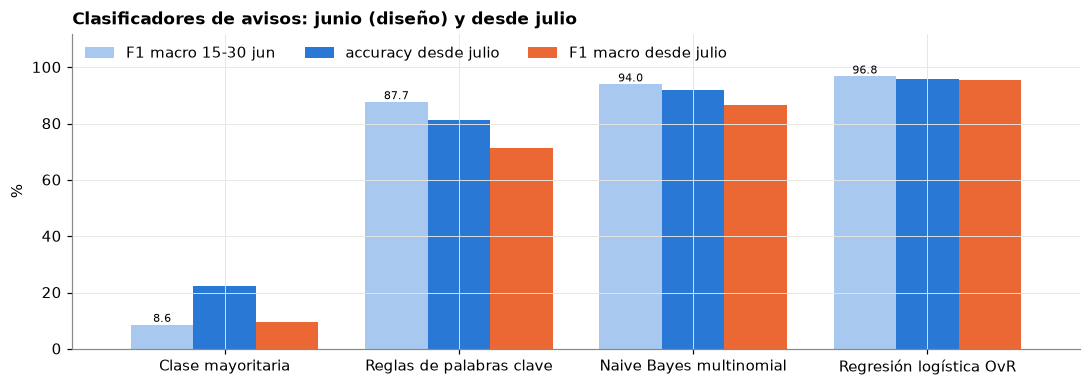

In [ ]:
# Tasa de aprendizaje de la regresión logística elegida SOLO con los avisos de junio
def regresion_logistica(lr):
    return (feature_extraction.TFIDF(on="texto")
            | multiclass.OneVsRestClassifier(linear_model.LogisticRegression(optimizer=optim.SGD(lr))))


junio = [(x, y) for x, y in flujo_avisos() if x["momento"] < pd.Timestamp("2016-07-01")]
error_junio = {}
for lr in [0.01, 0.1, 0.5, 1.0, 2.0, 5.0, 10.0]:
    reg, _ = prequential_texto(regresion_logistica(lr), junio)
    error_junio[lr] = round(100 * reg["error"].mean(), 1)
LR_ELEGIDA = min(error_junio, key=error_junio.get)
print("Error en junio según la tasa de aprendizaje (%):", error_junio)
print("Tasa elegida:", LR_ELEGIDA)

# Comparación de clasificadores: se eligen con junio (15-30) y se evalúan desde julio
MODELOS_TEXTO = {
    "Clase mayoritaria": ClaseMayoritaria,
    "Reglas de palabras clave": ReglasPalabrasClave,
    "Naive Bayes multinomial": lambda: feature_extraction.BagOfWords(on="texto") | naive_bayes.MultinomialNB(),
    "Regresión logística OvR": lambda: regresion_logistica(LR_ELEGIDA),
}
NB_TEXTO, LR_TEXTO = "Naive Bayes multinomial", "Regresión logística OvR"
registros_texto = {nombre: prequential_texto(fab())[0] for nombre, fab in MODELOS_TEXTO.items()}
reg_nb, reg_lr = registros_texto[NB_TEXTO], registros_texto[LR_TEXTO]
tabla_texto = pd.DataFrame({n: {"F1 macro 15-30 jun": resumen_texto(r, INICIO_DISENO, INICIO_EVALUACION)["F1 macro (%)"],
                                "accuracy desde julio": resumen_texto(r)["accuracy (%)"],
                                "F1 macro desde julio": resumen_texto(r)["F1 macro (%)"]}
                            for n, r in registros_texto.items()}).T

ax = tabla_texto.plot.bar(color=["#a9c8ef", AZUL, NARANJA], figsize=(10, 3.6), rot=0, width=0.8)
ax.bar_label(ax.containers[0], fmt="%.1f", fontsize=7.5)
ax.set_ylim(0, 112); ax.set_ylabel("%"); ax.set_title("Clasificadores de avisos: junio (diseño) y desde julio")
ax.legend(frameon=False, ncol=3, loc="upper left")
plt.tight_layout(); plt.show()
print(tabla_texto.round(1).to_string())

- La tasa de aprendizaje con menos error en junio es **5** (con la de por defecto, 0,01, falla el 60 % de los avisos de junio: aprende demasiado despacio).
- **En junio la regresión logística ya es la mejor** (F1 macro del 96,8 %, frente al 94,0 % del Naive Bayes y el 87,7 % de las reglas), así que se elige ella.
- **Desde julio la diferencia crece:** la regresión logística mantiene una F1 macro del 95,6 % (95,9 % de *accuracy*), mientras que el Naive Bayes baja al 86,5 % y las reglas, que no aprenden, al 71,4 %. La caída está donde predecía el razonamiento: en la reorganización de categorías (apartado 4.8.3).

### 4.8.3 Drift en los avisos

- ***Data drift*:** ¿se detecta la llegada de los turistas **sin etiquetas**? Vigilamos con ADWIN (con el mismo nivel de significación que en el resto del cuaderno, `delta=0,05`) una señal por aviso: 1 si parece inglés, según tenga más palabras vacías inglesas que francesas.
- ***Concept drift*:** ¿se adapta cada modelo a la reorganización de categorías? Comparamos el Naive Bayes sin olvido, el Naive Bayes con un **factor de olvido** programado por nosotros (antes de aprender cada aviso, todos los conteos se multiplican por λ = 0,998: memoria de unos 500 avisos, 3-4 semanas) y la regresión logística.

In [ ]:
# Data drift sin etiquetas: ¿parece inglés cada aviso? Señal vigilada con ADWIN
PALABRAS_EN = {"the", "is", "no", "not", "my", "i", "at", "to", "any", "was", "where", "how", "please", "thanks",
               "can't", "couldn't", "won't", "don't", "doesn't", "all", "a", "had", "there", "it", "in", "for", "you"}
PALABRAS_FR = {"le", "la", "les", "de", "du", "des", "je", "pas", "plus", "est", "a", "une", "un", "il", "mon", "ma",
               "sur", "pour", "ne", "que", "en", "et", "c'est", "j'ai", "on", "ce", "se", "au"}


def parece_ingles(texto):
    """Detector de idioma sin etiquetas: ¿más palabras vacías inglesas que francesas?"""
    palabras = re.findall(r"[a-z']+", normalizar(texto))
    return int(sum(w in PALABRAS_EN for w in palabras) > sum(w in PALABRAS_FR for w in palabras))


senal_idioma = pd.Series([parece_ingles(x["texto"]) for x, _ in flujo_avisos()], index=avisos["momento"])
print(f"La regla acierta el idioma en el {100 * (senal_idioma.values == (avisos['idioma'] == 'en').values).mean():.1f} % de los avisos")

detecciones_idioma = vigilar(drift.ADWIN(delta=0.05), senal_idioma.items())[1]
print("ADWIN sobre el idioma:", ", ".join(f"{t:%d-%m %H:%M}" for t in detecciones_idioma))

La regla acierta el idioma en el 97.5 % de los avisos
ADWIN sobre el idioma: 07-07 22:03, 06-09 08:47


ADWIN sobre el error del Naive Bayes: 12-08, 12-09, 18-09


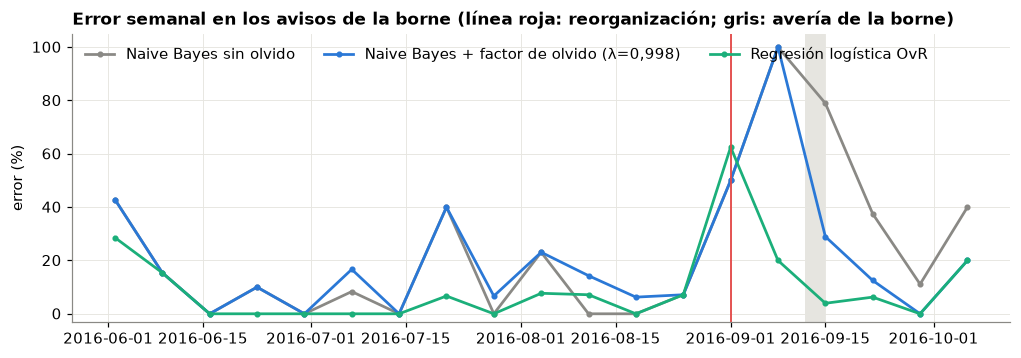

,accuracy (%),F1 macro (%),error en avisos de la borne desde el 1-sep (%)
Naive Bayes sin olvido,92.0,86.5,70.4
"Naive Bayes + factor de olvido (λ=0,998)",93.2,91.6,35.2
Regresión logística OvR,95.9,95.6,9.6


In [ ]:
# Concept drift: Naive Bayes sin olvido, con factor de olvido y regresión logística ante la reorganización de categorías
class MultinomialNBConOlvido(naive_bayes.MultinomialNB):
    """MultinomialNB con factor de olvido: antes de aprender cada aviso, todos los conteos se multiplican por `olvido`."""

    def __init__(self, alpha=1.0, olvido=0.998):
        super().__init__(alpha=alpha)
        self.olvido = olvido

    def learn_one(self, x, y):
        for conteos in (self.class_counts, self.class_totals, *self.feature_counts.values()):
            for clase in conteos:
                conteos[clase] *= self.olvido
        super().learn_one(x, y)


reg_olvido, _ = prequential_texto(feature_extraction.BagOfWords(on="texto") | MultinomialNBConOlvido(olvido=0.998))
registros_olvido = {"Naive Bayes sin olvido": reg_nb, "Naive Bayes + factor de olvido (λ=0,998)": reg_olvido,
                "Regresión logística OvR": reg_lr}
print("ADWIN sobre el error del Naive Bayes:",
      ", ".join(f"{t:%d-%m}" for t in vigilar(drift.ADWIN(delta=0.05), zip(reg_nb["revelada"], reg_nb["error"]))[1]))

fig, ax = plt.subplots(figsize=(11, 3.4))
for (nombre, r), color in zip(registros_olvido.items(), [GRIS, AZUL, VERDE]):
    s = r[r["causa"] == "averia_estacion"]["error"].resample("W-SUN").mean() * 100
    ax.plot(s.index - pd.Timedelta(days=3), s.values, color=color, lw=1.8, marker="o", ms=3, label=nombre)
ax.axvline(REORGANIZACION, color=ROJO, lw=1.2)
ax.axvspan(*AVERIA_BORNE, color=SOMBRA, lw=0, zorder=0)
ax.set_ylim(-3, 105)
ax.set_title("Error semanal en los avisos de la borne (línea roja: reorganización; gris: avería de la borne)")
ax.set_ylabel("error (%)")
ax.legend(frameon=False, ncol=3, loc="upper left")
plt.show()
pd.DataFrame({n: resumen_texto(r) for n, r in registros_olvido.items()}).T

- ***Data drift*:** la regla de idioma acierta el 97,5 % de los avisos y **ADWIN detecta sin etiquetas la llegada de los turistas el 7 de julio y su marcha el 6 de septiembre**. Los modelos absorben el cambio de idioma solos: el detector sirve para **avisar** (por ejemplo, para responder en inglés), no para reentrenar.
- ***Concept drift*:** el Naive Bayes sin olvido sigue enviando a `averia` el **70 %** de los avisos de la borne. ADWIN sobre su error no lo detecta hasta el **12 de septiembre**, con la avalancha de la avería, porque la clase afectada es minoritaria (unos 3 avisos al día de 20), y antes da una falsa alarma el 12 de agosto. Con **factor de olvido** el error en la borne baja al **35 %**, y la **regresión logística** se adapta sola: **10 %**, sin detector ni olvido programado.

**Elección: TF-IDF + regresión logística One-vs-Rest** (tasa 5), elegida con junio y confirmada desde julio: es la más precisa y la que mejor se adapta al cambio de categorías. Junto a ella dejamos un vigilante **sin etiquetas**, ADWIN sobre el idioma. Si se prefiriera un Naive Bayes, debería llevar factor de olvido.

## 4.9 Sistema anticipativo frente a sistema reactivo: ¿quién avisa antes?

Al equipo de redistribución le llegan dos avisos del mismo problema: la **alerta del ARF** (sistema anticipativo) y las **quejas que el clasificador del apartado 4.8 envía como `sin_bicis`** (sistema reactivo). Comparamos cuándo llega cada uno en cada **vaciado** de *pomme* desde julio: cada racha de medias horas seguidas con 2 bicis o menos en la que algún usuario se queja.
- **Queja:** la primera queja del vaciado que el clasificador envía como `sin_bicis`.
- **Alerta:** la primera alerta del ARF que apuntaba a ese vaciado (emitida en *t* para *t* + 2 h dentro del vaciado), si llegó antes de la queja.
- **Sensor:** el momento en que la estación se queda con 2 bicis o menos. El equipo también podría verlo en los sensores: la queja no aporta información nueva, pero **marca el momento en que el problema llega a un usuario**, y lo que interesa es cuánto margen da la alerta antes de ese momento.

442 quejas enviadas a sin_bicis desde julio; 412 caen en 160 vaciados
La alerta llega antes que la primera queja en el 46 % de los vaciados (antelación mediana: 2.3 h); el sensor, una mediana de 1 minutos antes


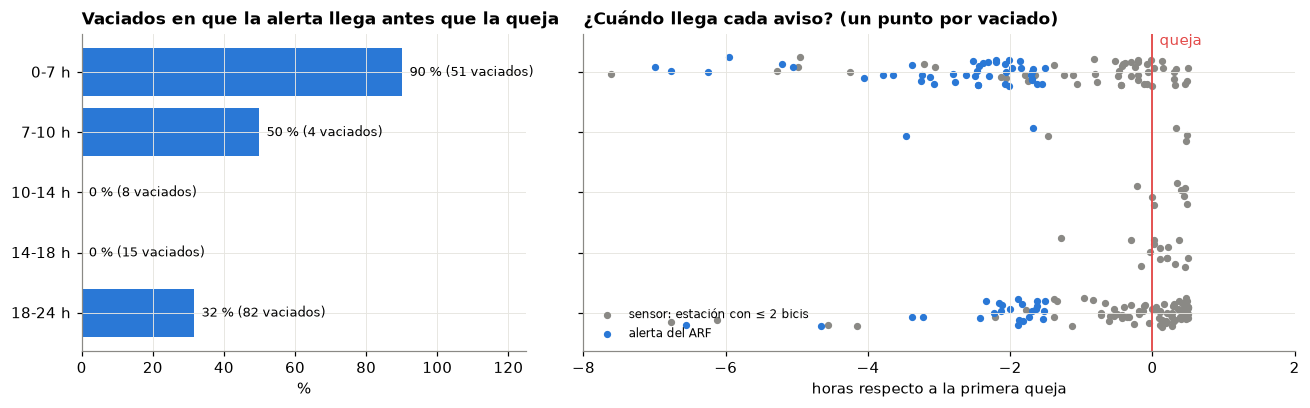

In [ ]:
# Cada vaciado de pomme desde julio con quejas: cuándo llegan la alerta del ARF, el sensor (estación vacía) y la primera queja
H = pd.Timedelta("1h")
vacia = flujo["bicis"] <= UMBRAL_POCAS                            # lo que predice la alerta: 2 bicis o menos
id_vaciado = (vacia != vacia.shift()).cumsum()
inicio_vaciado = flujo.index.to_series().groupby(id_vaciado).transform("min")

# Quejas: los avisos que la regresión logística del apartado 4.8 envía a sin_bicis (no la causa real del generador)
momentos_queja = reg_lr[(reg_lr["y_pred"] == "sin_bicis") & (reg_lr.index >= INICIO_EVALUACION)].index
media_hora = momentos_queja.ceil("30min")                         # instancia del flujo de sensores de cada queja
en_vaciado = np.array([m in vacia.index and vacia[m] for m in media_hora])
quejas = pd.DataFrame({"queja": momentos_queja[en_vaciado], "vaciado": id_vaciado[media_hora[en_vaciado]].values,
                       "sensor": inicio_vaciado[media_hora[en_vaciado]].values})
vaciados = quejas.groupby("vaciado").agg(sensor=("sensor", "first"), queja=("queja", "min"))


def primera_alerta(pred, vaciados):
    """Primera alerta que apunta a cada vaciado (emitida en t para t + 2 h dentro del vaciado) antes de su primera queja."""
    emitidas = pred.index[pred.astype(bool).values]
    salida = []
    for sensor, queja in zip(vaciados["sensor"], vaciados["queja"]):
        c = emitidas[(emitidas >= sensor - 2 * H) & (emitidas <= queja.ceil("30min") - 2 * H)]
        salida.append(c[0] if len(c) else pd.NaT)
    return pd.Series(salida, index=vaciados.index)


vaciados["alerta"] = primera_alerta(reg_arf["y_pred"], vaciados)
antelacion_alerta = (vaciados["queja"] - vaciados["alerta"]) / H
antelacion_sensor = (vaciados["queja"] - vaciados["sensor"]) / H
FRANJAS = ["0-7 h", "7-10 h", "10-14 h", "14-18 h", "18-24 h"]
franja = pd.cut(vaciados["sensor"].dt.hour, [0, 7, 10, 14, 18, 24], right=False, labels=FRANJAS)
print(f"{len(momentos_queja)} quejas enviadas a sin_bicis desde julio; {en_vaciado.sum()} caen en {len(vaciados)} vaciados")
print(f"La alerta llega antes que la primera queja en el {100 * vaciados['alerta'].notna().mean():.0f} % de los vaciados "
      f"(antelación mediana: {antelacion_alerta.median():.1f} h); el sensor, una mediana de {60 * antelacion_sensor.median():.0f} minutos antes")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1, 1.6]}, sharey=True)
pct = 100 * vaciados["alerta"].notna().groupby(franja, observed=False).mean()
n = franja.value_counts().reindex(FRANJAS)
a1.barh(FRANJAS, pct.reindex(FRANJAS), color=AZUL)
for j, (p, k) in enumerate(zip(pct.reindex(FRANJAS), n)):
    a1.text(p + 2, j, f"{p:.0f} % ({k} vaciados)", va="center", fontsize=8.5)
a1.set_xlim(0, 125); a1.invert_yaxis(); a1.set_xlabel("%"); a1.set_title("Vaciados en que la alerta llega antes que la queja")
pos = franja.cat.codes.to_numpy() + np.random.default_rng(SEMILLA).uniform(-0.25, 0.25, len(franja))
a2.scatter(-antelacion_sensor, pos, s=14, color=GRIS, label="sensor: estación con ≤ 2 bicis")
a2.scatter(-antelacion_alerta, pos, s=14, color=AZUL, label="alerta del ARF")
a2.axvline(0, color=ROJO, lw=1.2); a2.text(0.1, -0.45, "queja", color=ROJO)
a2.set_xlim(-8, 2); a2.set_xlabel("horas respecto a la primera queja")
a2.set_title("¿Cuándo llega cada aviso? (un punto por vaciado)"); a2.legend(frameon=False, fontsize=8, loc="lower left")
plt.tight_layout(); plt.show()

- **El sistema anticipativo es más rápido en casi la mitad de los vaciados:** la alerta del ARF llega antes que la primera queja en el 46 % de los 160 vaciados con quejas desde julio, con una antelación mediana de 2,3 horas, y casi siempre antes incluso de que la estación se vacíe. En el resto, el primer aviso es la queja.
- **Depende de la hora.** De madrugada (0-7 h) la alerta se adelanta casi siempre (90 %): el vaciado nocturno es el patrón que el ARF ha aprendido. Entre las 10 y las 18 h no se adelanta nunca y, en la tarde-noche (18-24 h), la franja con más vaciados, solo en un tercio: son vaciados inesperados que el ARF no ve venir, porque en junio esas horas pocas veces acababan en alerta (apartado 4.2.2).
- **La queja llega a la vez que el sensor** (una mediana de un minuto de diferencia), salvo de madrugada, cuando la estación lleva un rato vacía antes de que alguien la necesite. El sistema reactivo no da antelación, solo confirma el problema cuando ya afecta a un usuario; la única antelación real es la del ARF.

### El umbral de decisión

La alerta salta cuando la probabilidad de quedarse con 2 bicis o menos supera 0,5. Con un umbral más bajo salta antes y en más vaciados, a cambio de más alertas al día. Como el resto de decisiones de diseño, el umbral se elige **con junio**: el más bajo con el que el ARF sigue acertando al menos tanto como la persistencia (apartado 4.4). Después medimos desde julio cómo cambia la carrera entre los dos sistemas.

Persistencia en junio: 75.7 % | umbral elegido con junio: 0.35
      accuracy en junio (%)  vaciados avisados antes de la queja (%)  alertas por día (medias horas)
0.50                   82.5                                     46.2                            18.6
0.45                   80.8                                     51.9                            20.6
0.40                   77.6                                     60.0                            22.7
0.35                   75.9                                     70.6                            25.4
0.30                   73.8                                     77.5                            28.1
0.25                   70.2                                     84.4                            30.8
0.20                   66.2                                     90.6                            33.4


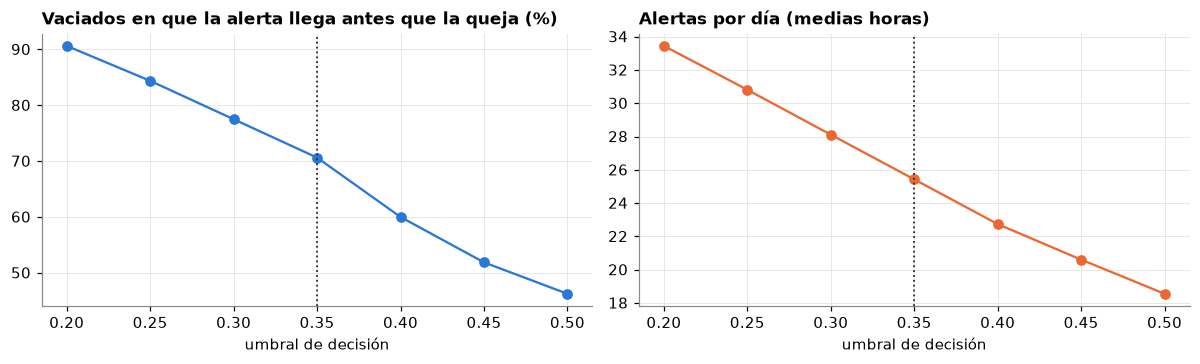

In [ ]:
# Umbral de decisión: elegido con junio y evaluado desde julio (vaciados avisados antes de la queja y alertas por día)
def prequential_probabilidad(modelo, instancias, retraso=HORIZONTE):
    """Como prequential, pero guarda la probabilidad de alerta que da el modelo en lugar de la clase."""
    pendientes, filas_p = collections.deque(), []
    for x, y in instancias:
        t = x["momento"]
        while pendientes and pendientes[0][0] + retraso <= t:
            t0, x0, y0, p0 = pendientes.popleft()
            filas_p.append((t0, y0, p0))
            modelo.learn_one(x0, y0)
        xm = variables_modelo(x)
        pendientes.append((t, xm, y, modelo.predict_proba_one(xm).get(True, 0.0)))
    return pd.DataFrame(filas_p, columns=["momento", "y", "proba"]).set_index("momento")


UMBRALES = [0.5, 0.45, 0.4, 0.35, 0.3, 0.25, 0.2]
prob_junio = prequential_probabilidad(forest.ARFClassifier(n_models=ARBOLES, seed=SEMILLA), solo_junio(flujo_bicis()))
prob_junio = prob_junio[prob_junio.index >= INICIO_DISENO]
acc_junio = {u: 100 * ((prob_junio["proba"] >= u) == prob_junio["y"].astype(bool)).mean() for u in UMBRALES}
acc_persistencia = tabla_modelos.loc["Persistencia", "accuracy 15-30 jun"]
UMBRAL = min(u for u in UMBRALES if acc_junio[u] >= acc_persistencia)

prob = prequential_probabilidad(forest.ARFClassifier(n_models=ARBOLES, seed=SEMILLA), flujo_bicis())
desde_julio = prob[prob.index >= INICIO_EVALUACION]
dias = (desde_julio.index.max() - INICIO_EVALUACION).days
efecto = pd.DataFrame({u: {"accuracy en junio (%)": acc_junio[u],
                           "vaciados avisados antes de la queja (%)": 100 * primera_alerta(prob["proba"] >= u, vaciados).notna().mean(),
                           "alertas por día (medias horas)": (desde_julio["proba"] >= u).sum() / dias}
                       for u in UMBRALES}).T

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.4), sharex=True)
a1.plot(efecto.index, efecto["vaciados avisados antes de la queja (%)"], "o-", color=AZUL)
a1.set_title("Vaciados en que la alerta llega antes que la queja (%)")
a2.plot(efecto.index, efecto["alertas por día (medias horas)"], "o-", color=NARANJA)
a2.set_title("Alertas por día (medias horas)")
for ax in (a1, a2):
    ax.axvline(UMBRAL, color=TINTA, ls=":", lw=1.2); ax.set_xlabel("umbral de decisión")
plt.tight_layout(); plt.show()
print(f"Persistencia en junio: {acc_persistencia:.1f} % | umbral elegido con junio: {UMBRAL}")
print(efecto.round(1).to_string())

- Con el umbral elegido con junio (**0,35**, el más bajo con el que el ARF acierta al menos tanto como la persistencia en junio: 75,9 % frente a 75,7 %), la alerta llega antes que la queja en el **71 %** de los vaciados, frente al 46 % con 0,5.
- El precio son más alertas: unas 25 medias horas al día frente a 19, un 37 % más. Bajar más el umbral seguiría adelantando la alerta (91 % de los vaciados con 0,2), pero con una *accuracy* en junio peor que la persistencia: muchas de esas alertas serían falsas.
- Cuánto vale una alerta de más (un desplazamiento del camión) frente a una de menos (usuarios sin bici) es una decisión del operador; el criterio de junio es una forma de fijar el umbral sin mirar el futuro.

# 5. Resultados

**La alerta.** Elegimos el *Adaptive Random Forest* con los datos de junio, sabiendo que allí no era el que más acertaba: el Hoeffding Tree le sacaba casi dos puntos (84,3 % frente a 82,5 %). La apuesta era que un bosque que renueva sus árboles aguantaría mejor los cambios del verano que un árbol que no revisa sus divisiones, y salió bien: de julio a octubre el ARF fue el mejor modelo todos los meses, con un 83,4 % de *accuracy*, frente al 80,5 % del Hoeffding Tree y el 75,2 % de la persistencia. Lo que más usa son la hora y las bicis que hay en ese momento; el tiempo no aporta: sin ninguna variable meteorológica falla incluso algo menos.

**El sistema en marcha.** El *concept drift* real es leve: los detectores dan alarmas en fechas distintas, pero al congelar el modelo tras la primera coincidencia (14 de agosto) sigue acertando igual, y el aprendizaje online absorbe los cambios. Los datos sí cambian: el uso de la estación cae un 25 % en vacaciones y se recupera con la vuelta a clase, y la temperatura baja de golpe a mediados de septiembre. Los detectores lo ven sin etiquetas, pero ninguno de los dos cambios empeora el modelo. El clustering de los días marca 8 laborables en los que la estación no se llena; esos días la alerta acierta casi 9 puntos menos (76,8 % frente a 85,5 %).

**Ante un cambio fuerte.** Cuando el sistema pasa de golpe a recibir los datos de otra estación, los tres detectores lo detectan, pero tardan de 2 a 4,5 días. La mejor forma de adaptarse es el propio ARF (24,9 % de error), que sustituye poco a poco los árboles que empeoran. Reiniciar el modelo cada vez que salta un detector es peor que no hacer nada (28,8-29,6 % frente a 28,4 %): las falsas alarmas lo reinician antes del cambio y después se encadenan los reinicios.

**Los dos sistemas.** El clasificador de quejas, una regresión logística con TF-IDF elegida con junio, acierta el 96 % de los avisos desde julio, frente al 81 % de unas reglas de palabras clave, y se adapta solo cuando el operador reorganiza sus categorías, algo que un Naive Bayes sin olvido no consigue (falla el 70 % de los avisos de la categoría nueva, frente al 10 %). En la carrera entre los dos sistemas, la alerta llega antes que la primera queja en el 46 % de los vaciados, con unas 2,3 horas de margen, y en el 71 % con el umbral de decisión elegido con junio. La queja, en cambio, llega casi a la vez que el sensor ve la estación vacía: no da antelación. La alerta va por delante de madrugada, cuando el vaciado es el habitual, pero nunca a mediodía y solo en un tercio de los vaciados de la tarde y la noche, cuando el vaciado es inesperado y más usuarios lo sufren.

# 6. Análisis crítico y conclusiones

El trabajo deja varias ideas que van más allá de esta estación. La primera es que las decisiones de construcción del flujo (frecuencia, horizonte, retraso de la etiqueta) y tomar todas las decisiones de diseño solo con los datos disponibles antes del despliegue pesan tanto como el modelo. La segunda, que hay que medir donde importa: la *accuracy* trata igual todas las medias horas, y solo al comparar la alerta con las quejas se ve que acierta sobre todo cuando menos falta hace. La tercera, que *data drift* y *concept drift* son distintos: los datos cambian mucho en verano sin que el modelo empeore, así que una alarma de *data drift* sirve para avisar, no para reentrenar. La cuarta, que para adaptarse importa más olvidar bien y no reaccionar a falsas alarmas que detectar rápido: el ARF y la regresión logística, que olvidan de forma natural, superan a cualquier reinicio. Y la última, que un *concept drift* que afecta a una clase minoritaria tarda en verse en el error global. Con todo, el objetivo se cumple: la alerta mejora a la persistencia, los cambios se detectan sin etiquetas y, con el umbral elegido, el sistema anticipativo avisa antes que el reactivo en siete de cada diez vaciados.

Hay que leer los resultados con cautela. Las quejas son sintéticas: se generan a partir del estado real de la estación, pero sus cifras absolutas dependen del generador, y lo que se puede extrapolar son las comparaciones. Trabajamos con una sola estación y un solo verano, y el cambio fuerte del apartado 4.7 es artificial. Los parámetros de los detectores se fijaron a priori, razonando, pero no se validaron en otro periodo.

Como trabajo futuro, el paso natural es completar el problema de la redistribución: predecir también la demanda y el llenado de las estaciones y fijar el umbral de la alerta con los costes reales del operador. En el sistema de quejas, vigilar el error de cada clase por separado permitiría ver antes los cambios que afectan a categorías pequeñas.

# 7. Referencias

[1] S. Wang, T. He, D. Zhang, Y. Shu, Y. Liu, Y. Gu, C. Liu, H. Lee y S. H. Son, "BRAVO: Improving the rebalancing operation in bike sharing with rebalancing range prediction", *Proc. ACM Interactive, Mobile, Wearable and Ubiquitous Technologies*, vol. 2, n.º 1, pp. 1-22, 2018.

[2] J. Gama, I. Žliobaitė, A. Bifet, M. Pechenizkiy y A. Bouchachia, "A survey on concept drift adaptation", *ACM Computing Surveys*, vol. 46, n.º 4, 2014.

[3] M. Halford, "A short introduction and conclusion to the OpenBikes 2016 Challenge", 2017. https://maxhalford.github.io/blog/openbikes-challenge/

[4] H. M. Gomes, A. Bifet, J. Read, J. P. Barddal, F. Enembreck, B. Pfahringer, G. Holmes y T. Abdessalem, "Adaptive random forests for evolving data stream classification", *Machine Learning*, vol. 106, pp. 1469-1495, 2017.